In [29]:
import pandas as pd
import os
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# advance.bk

In [2]:
file_path = r"D:\Project_Github\set_fear_index\dataset\parquet\ADVANC.BK.parquet"

df = pd.read_parquet(file_path)

df

Price,Open,High,Low,Close,Volume,daily_return,momentum_20d,vol_z,target
Date,,,,,,,,,
2016-11-11,96.220726,96.220726,95.258518,95.579254,9496400,NaN,NaN,NaN,2
2016-11-14,94.937805,95.258541,93.654861,93.654861,10092400,-0.020134,NaN,NaN,2
2016-11-15,93.975586,94.617058,93.654850,93.975586,6678100,0.003425,NaN,NaN,2
2016-11-16,94.296317,94.617053,92.051167,92.371902,11704300,-0.017065,NaN,NaN,2
2016-11-17,92.371898,93.013370,92.051163,92.051163,6044800,-0.003472,NaN,NaN,2
...,...,...,...,...,...,...,...,...,...
2026-11-05,337.000000,343.000000,335.000000,342.000000,6656100,0.011834,-0.005814,0.292539,2
2026-11-06,338.000000,341.000000,336.000000,338.000000,6223100,-0.011696,-0.008798,0.021663,2
2026-11-09,338.000000,340.000000,336.000000,339.000000,2483000,0.002959,0.000000,-1.759097,2


In [3]:
#daily_return = df["Close"].pct_change()
df["daily_return"] = (df["Close"]/df["Close"].shift(1))-1
df["daily_return"]

Date
2016-11-11         NaN
2016-11-14   -0.020134
2016-11-15    0.003425
2016-11-16   -0.017065
2016-11-17   -0.003472
                ...   
2026-11-05    0.011834
2026-11-06   -0.011696
2026-11-09    0.002959
2026-11-10   -0.002950
2026-11-11    0.017751
Name: daily_return, Length: 2426, dtype: float64

In [4]:
df["momentum_20d"] = (df["Close"]/df["Close"].shift(20))-1
df["momentum_20d"]

Date
2016-11-11         NaN
2016-11-14         NaN
2016-11-15         NaN
2016-11-16         NaN
2016-11-17         NaN
                ...   
2026-11-05   -0.005814
2026-11-06   -0.008798
2026-11-09    0.000000
2026-11-10    0.008955
2026-11-11    0.029940
Name: momentum_20d, Length: 2426, dtype: float64

In [5]:
vol_mean = df["Volume"].shift(1).rolling(window=20).mean()
vol_std = df["Volume"].shift(1).rolling(window=20).std()

df["vol_z"] = (df["Volume"] - vol_mean) / vol_std
df["vol_z"]

Date
2016-11-11         NaN
2016-11-14         NaN
2016-11-15         NaN
2016-11-16         NaN
2016-11-17         NaN
                ...   
2026-11-05    0.292539
2026-11-06    0.021663
2026-11-09   -1.759097
2026-11-10    0.094538
2026-11-11    0.996664
Name: vol_z, Length: 2426, dtype: float64

In [6]:
df

Price,Open,High,Low,Close,Volume,daily_return,momentum_20d,vol_z,target
Date,,,,,,,,,
2016-11-11,96.220726,96.220726,95.258518,95.579254,9496400,NaN,NaN,NaN,2
2016-11-14,94.937805,95.258541,93.654861,93.654861,10092400,-0.020134,NaN,NaN,2
2016-11-15,93.975586,94.617058,93.654850,93.975586,6678100,0.003425,NaN,NaN,2
2016-11-16,94.296317,94.617053,92.051167,92.371902,11704300,-0.017065,NaN,NaN,2
2016-11-17,92.371898,93.013370,92.051163,92.051163,6044800,-0.003472,NaN,NaN,2
...,...,...,...,...,...,...,...,...,...
2026-11-05,337.000000,343.000000,335.000000,342.000000,6656100,0.011834,-0.005814,0.292539,2
2026-11-06,338.000000,341.000000,336.000000,338.000000,6223100,-0.011696,-0.008798,0.021663,2
2026-11-09,338.000000,340.000000,336.000000,339.000000,2483000,0.002959,0.000000,-1.759097,2


In [7]:
conditions = [
    (df["daily_return"].shift(-1) < 0) & (df["vol_z"] >= 1.5),  
    (df["daily_return"].shift(-1) > 0) & (df["vol_z"] >= 1.5),  
]

choices = [0, 1]

df["target"] = np.select(conditions, choices, default=2)
df

Price,Open,High,Low,Close,Volume,daily_return,momentum_20d,vol_z,target
Date,,,,,,,,,
2016-11-11,96.220726,96.220726,95.258518,95.579254,9496400,NaN,NaN,NaN,2
2016-11-14,94.937805,95.258541,93.654861,93.654861,10092400,-0.020134,NaN,NaN,2
2016-11-15,93.975586,94.617058,93.654850,93.975586,6678100,0.003425,NaN,NaN,2
2016-11-16,94.296317,94.617053,92.051167,92.371902,11704300,-0.017065,NaN,NaN,2
2016-11-17,92.371898,93.013370,92.051163,92.051163,6044800,-0.003472,NaN,NaN,2
...,...,...,...,...,...,...,...,...,...
2026-11-05,337.000000,343.000000,335.000000,342.000000,6656100,0.011834,-0.005814,0.292539,2
2026-11-06,338.000000,341.000000,336.000000,338.000000,6223100,-0.011696,-0.008798,0.021663,2
2026-11-09,338.000000,340.000000,336.000000,339.000000,2483000,0.002959,0.000000,-1.759097,2


In [8]:
df.to_parquet(r"D:\Project_Github\set_fear_index\dataset\parquet\ADVANC.BK.parquet")

# all

In [9]:
folder_path = Path(r"D:\Project_Github\set_fear_index\dataset\parquet")
for file_path in folder_path.iterdir():

    df = pd.read_parquet(file_path)

    #daily_return = df["Close"].pct_change()
    df["daily_return"] = (df["Close"]/df["Close"].shift(1))-1

    df["momentum_20d"] = (df["Close"]/df["Close"].shift(20))-1

    vol_mean = df["Volume"].shift(1).rolling(window=20).mean()
    vol_std = df["Volume"].shift(1).rolling(window=20).std()

    df["vol_z"] = (df["Volume"] - vol_mean) / vol_std

    conditions = [
        (df["daily_return"].shift(-1) < 0) & (df["vol_z"] >= 1.5),  
        (df["daily_return"].shift(-1) > 0) & (df["vol_z"] >= 1.5),  
    ]

    choices = [0, 1]

    df["target"] = np.select(conditions, choices, default=2)
    df.to_parquet(file_path)

# rank

## period

In [23]:
file_path_const = r"D:\Project_Github\set_fear_index\dataset\SET50_constituents_by_halfyear_2016_2026.csv"

df_const = pd.read_csv(file_path_const)

df_const

,period,symbol_1,symbol_2,symbol_3,symbol_4,symbol_5,symbol_6,symbol_7,symbol_8,symbol_9,...,symbol_41,symbol_42,symbol_43,symbol_44,symbol_45,symbol_46,symbol_47,symbol_48,symbol_49,symbol_50
0,2016_H1,ADVANC,AOT,BA,BANPU,BBL,BCP,BDMS,BEC,BH,...,SCCC,TASCO,TCAP,TMB,TOP,TPIPL,TRUE,TTW,TU,WHA
1,2016_H2,ADVANC,AOT,BA,BANPU,BBL,BCP,BDMS,BEC,BEM,...,SCC,TASCO,TCAP,TMB,TOP,TPIPL,TRUE,TTW,TU,WHA
2,2017_H1,ADVANC,AOT,BA,BANPU,BBL,BCP,BDMS,BEM,BH,...,SPRC,TCAP,THAI,TMB,TOP,TPIPL,TRUE,TU,WHA,NaN
3,2017_H2,ADVANC,AOT,BANPU,BBL,BDMS,BEM,BH,BJC,BLA,...,SCC,SCCC,SPRC,TCAP,TISCO,TMB,TOP,TPIPL,TRUE,TU
4,2018_H1,ADVANC,AOT,BANPU,BBL,BCP,BDMS,BEAUTY,BEM,BH,...,SCC,SPRC,TCAP,TISCO,TMB,TOP,TPIPP,TRUE,TU,WHA
5,2018_H2,ADVANC,AOT,BANPU,BBL,BDMS,BEAUTY,BEM,BGRIM,BH,...,SCB,SCC,SPRC,TCAP,TISCO,TMB,TOA,TOP,TRUE,TU
6,2019_H1,ADVANC,AOT,BANPU,BBL,BDMS,BEM,BGRIM,BH,BJC,...,SCC,SPRC,TCAP,TISCO,TMB,TOA,TOP,TRUE,TU,WHA
7,2019_H2,ADVANC,AOT,BANPU,BBL,BDMS,BEM,BGRIM,BH,BJC,...,SCB,SCC,TCAP,TISCO,TMB,TOA,TOP,TRUE,TU,WHA
8,2020_H1,ADVANC,AOT,AWC,BANPU,BBL,BDMS,BEM,BGRIM,BH,...,SCC,TCAP,TISCO,TMB,TOA,TOP,TRUE,TU,VGI,WHA
9,2020_H2,ADVANC,AOT,AWC,BBL,BDMS,BEM,BGRIM,BH,BJC,...,TCAP,TISCO,TMB,TOA,TOP,TRUE,TTW,TU,VGI,WHA


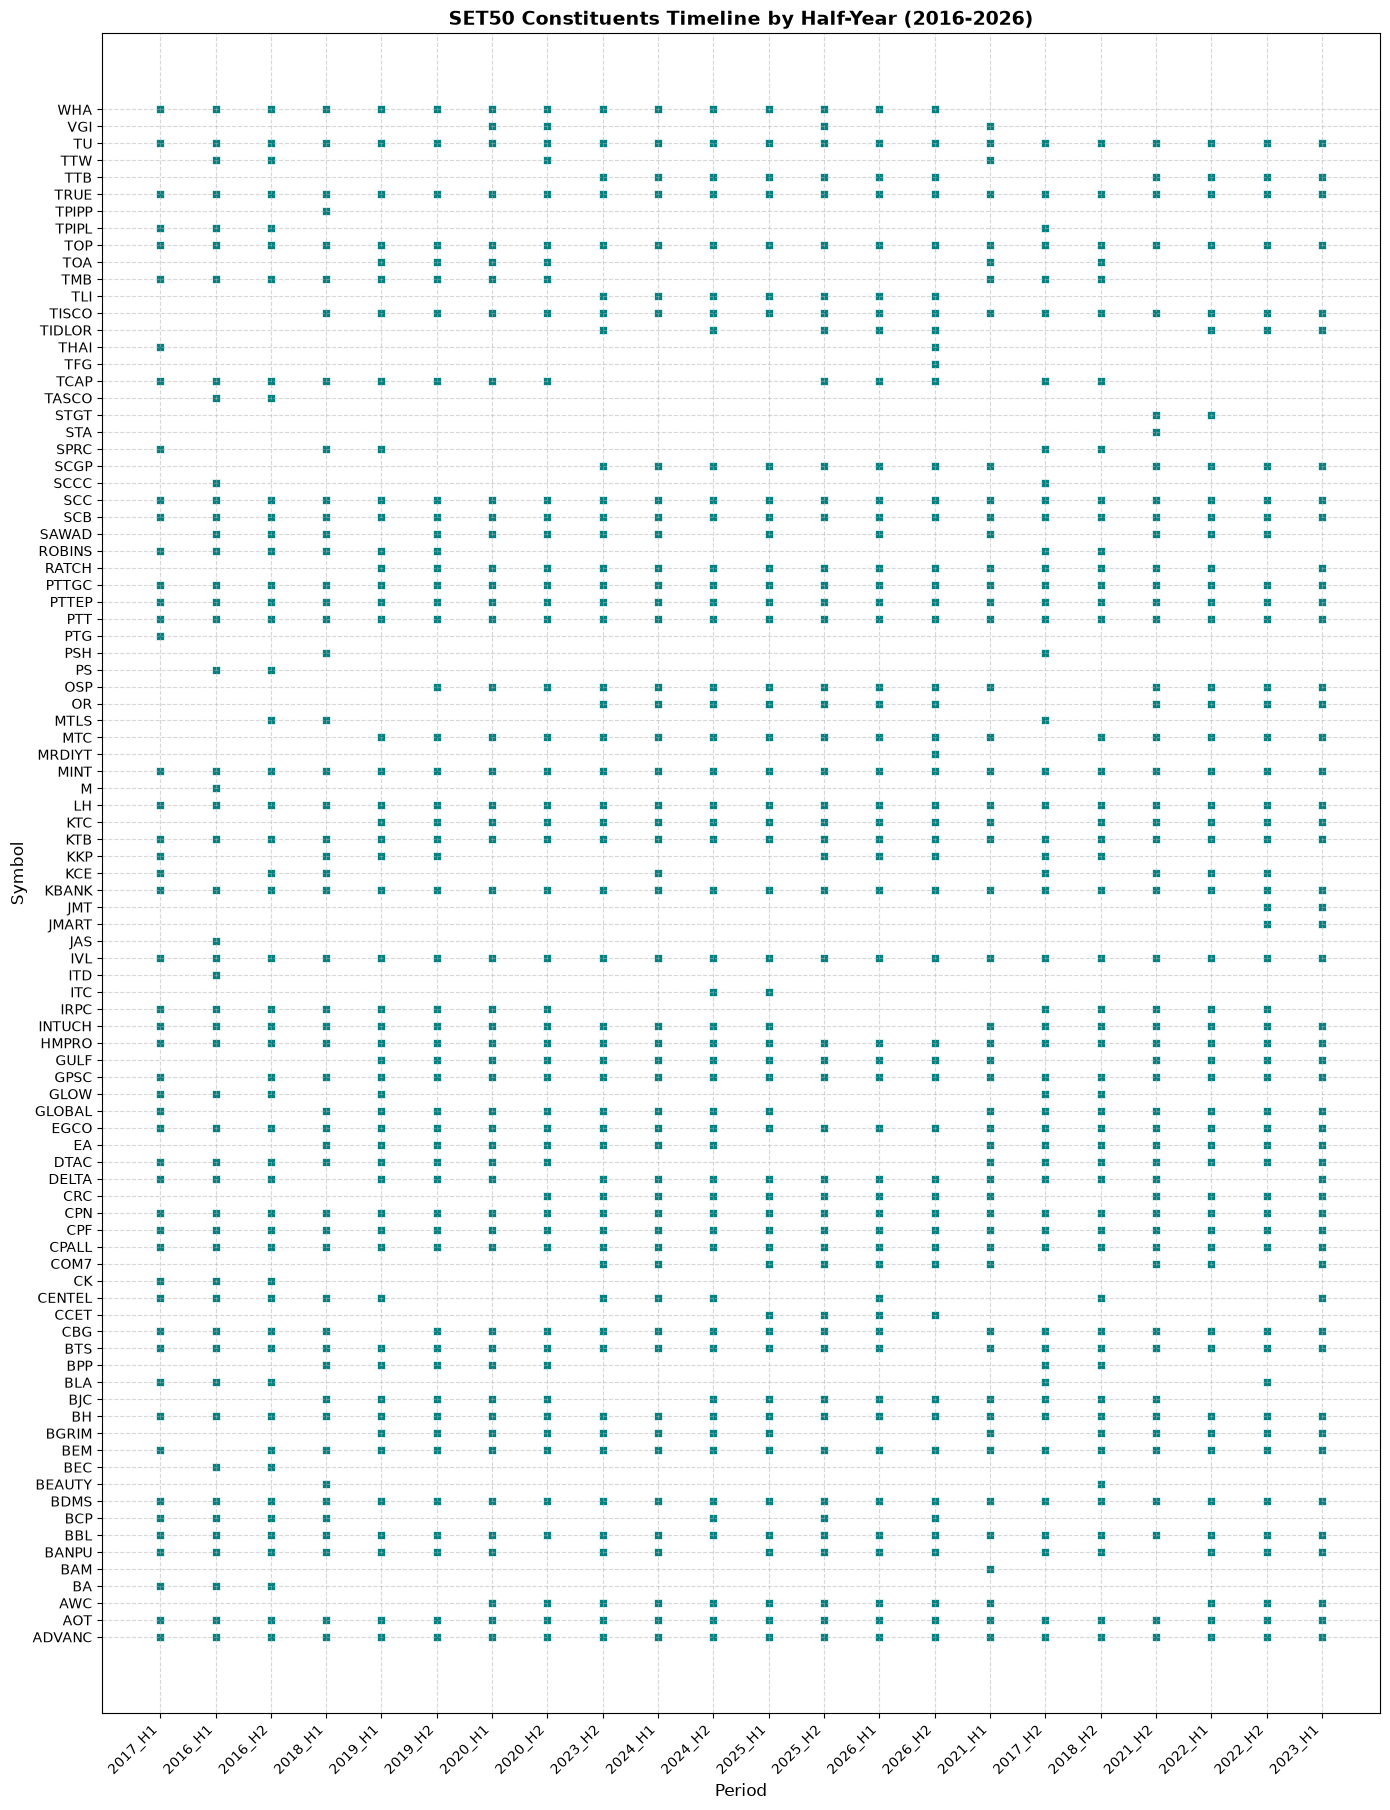

In [24]:
symbol_cols = [col for col in df_const.columns if col.startswith("symbol_")]
df_long = df_const.melt(
    id_vars=["period"],
    value_vars=symbol_cols,
    var_name="symbol_id",
    value_name="symbol",
)

df_long = df_long.dropna(subset=["symbol"])

df_long = df_long.sort_values(by="symbol", ascending=False)

plt.figure(figsize=(14, max(8, len(df_long["symbol"].unique()) * 0.2)))

sns.scatterplot(
    data=df_long,
    x="period",
    y="symbol",
    color="teal",
    marker="s",  
    s=40, 
)

plt.title(
    "SET50 Constituents Timeline by Half-Year (2016-2026)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Period", fontsize=12)
plt.ylabel("Symbol", fontsize=12)

plt.xticks(rotation=45, ha="right")

plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [20]:
file_path_declare = r"D:\Project_Github\set_fear_index\dataset\set50_declare_dates_2016_2026.csv"

df_declare = pd.read_csv(file_path_declare)

df_declare["effective_date"]

0     2016-01-01
1     2016-07-01
2     2017-01-01
3     2017-07-01
4     2018-01-01
5     2018-07-01
6     2019-01-02
7     2019-07-01
8     2020-01-01
9     2020-07-01
10    2021-01-01
11    2021-07-01
12    2022-01-01
13    2022-07-01
14    2023-01-01
15    2023-07-01
16    2024-01-02
17    2024-07-01
18    2025-01-01
19    2025-07-01
20    2026-01-01
21    2026-07-01
Name: effective_date, dtype: str

In [21]:
# 1. แปลง effective_date ให้เป็นรูปแบบ Datetime
df_declare["effective_date"] = pd.to_datetime(df_declare["effective_date"])

# 2. กำหนด Start Date คือ effective_date
df_declare["start_date"] = df_declare["effective_date"]


# 3. สร้างฟังก์ชันกำหนด End Date
def get_end_date(row):
  if row["effective_date"].month == 1:
    # รอบ H1 สิ้นสุด 30 มิถุนายนของปีนั้น
    return pd.Timestamp(f"{row['effective_date'].year}-06-30")
  else:
    # รอบ H2 สิ้นสุด 31 ธันวาคมของปีนั้น
    return pd.Timestamp(f"{row['effective_date'].year}-12-31")


df_declare["end_date"] = df_declare.apply(get_end_date, axis=1)

# ดูผลลัพธ์
print(df_declare[["effective_date", "start_date", "end_date"]])

   effective_date start_date   end_date
0      2016-01-01 2016-01-01 2016-06-30
1      2016-07-01 2016-07-01 2016-12-31
2      2017-01-01 2017-01-01 2017-06-30
3      2017-07-01 2017-07-01 2017-12-31
4      2018-01-01 2018-01-01 2018-06-30
5      2018-07-01 2018-07-01 2018-12-31
6      2019-01-02 2019-01-02 2019-06-30
7      2019-07-01 2019-07-01 2019-12-31
8      2020-01-01 2020-01-01 2020-06-30
9      2020-07-01 2020-07-01 2020-12-31
10     2021-01-01 2021-01-01 2021-06-30
11     2021-07-01 2021-07-01 2021-12-31
12     2022-01-01 2022-01-01 2022-06-30
13     2022-07-01 2022-07-01 2022-12-31
14     2023-01-01 2023-01-01 2023-06-30
15     2023-07-01 2023-07-01 2023-12-31
16     2024-01-02 2024-01-02 2024-06-30
17     2024-07-01 2024-07-01 2024-12-31
18     2025-01-01 2025-01-01 2025-06-30
19     2025-07-01 2025-07-01 2025-12-31
20     2026-01-01 2026-01-01 2026-06-30
21     2026-07-01 2026-07-01 2026-12-31


In [22]:
df_declare

,year,review_period,announcement_date,effective_date,source_url,evidence,start_date,end_date
0,2016,H1,2015-12-14,2016-01-01,https://mondovisione.com/media-and-resources/n...,SET release dated 2015-12-14 announces SET50 r...,2016-01-01,2016-06-30
1,2016,H2,2016-06-17,2016-07-01,https://mondovisione.com/news/news-centre/?pag...,Contemporaneous SET News Centre listing dated ...,2016-07-01,2016-12-31
2,2017,H1,2016-12-16,2017-01-01,https://mgronline.com/stockmarket/detail/95900...,MGR Online reports announcement on 2016-12-16 ...,2017-01-01,2017-06-30
3,2017,H2,2017-06-16,2017-07-01,https://mgronline.com/stockmarket/detail/96000...,MGR Online reports announcement on 2017-06-16 ...,2017-07-01,2017-12-31
4,2018,H1,2017-12-13,2018-01-01,https://media.set.or.th/set/Documents/2021/Dec...,SET constituent PDF published Dec 13 2017 for ...,2018-01-01,2018-06-30
5,2018,H2,2018-06-18,2018-07-01,https://media.set.or.th/set/Documents/2021/Dec...,SET constituent PDF published Jun 18 2018 for ...,2018-07-01,2018-12-31
6,2019,H1,2018-12-17,2019-01-02,https://digital.car.chula.ac.th/cgi/viewconten...,Chulalongkorn University thesis table lists SE...,2019-01-02,2019-06-30
7,2019,H2,2019-06-18,2019-07-01,https://www.kaohoon.com/news/international/301048,Kaohoon report dated Jun 18 2019 on H2 review;...,2019-07-01,2019-12-31
8,2020,H1,2019-12-18,2020-01-01,https://media.set.or.th/set/Documents/2022/Apr...,SET constituent PDF published Dec 18 2019 for ...,2020-01-01,2020-06-30
9,2020,H2,2020-06-15,2020-07-01,https://media.set.or.th/set/Documents/2022/Apr...,SET constituent PDF published Jun 15 2020 for ...,2020-07-01,2020-12-31


In [25]:
# เนื่องจากแถวตรงกันเป๊ะ นำ 'period' จาก df_const มาใส่ใน df_declare เพิ่มความชัวร์
df_declare["period"] = df_const["period"].values

## Volatility Rank

In [36]:
parquet_folder = Path(r"D:\Project_Github\set_fear_index\dataset\parquet")

# ตัวแปรสำหรับเก็บข้อมูลแยกตามรายชื่อหุ้น
stock_dfs_dict = defaultdict(list)

# 2. วนลูปทีละรอบ Period
for idx, row_dec in df_declare.iterrows():
  period = row_dec["period"]
  start_date = pd.to_datetime(row_dec["start_date"])
  end_date = pd.to_datetime(row_dec["end_date"])

  row_const = df_const.iloc[idx]
  symbol_cols = [col for col in df_const.columns if col.startswith("symbol_")]
  symbols = row_const[symbol_cols].dropna().tolist()

  print(
      f"กำลังประมวลผลรอบ: {period} | ช่วงวันที่: {start_date.date()} ถึง"
      f" {end_date.date()} | หุ้น: {len(symbols)} ตัว"
  )

  period_dfs = []

  # 3. โหลดไฟล์ Parquet ของหุ้น 50 ตัวในรอบนี้
  for sym in symbols:
    file_path = parquet_folder / f"{sym}.BK.parquet"

    if file_path.exists():
      df = pd.read_parquet(file_path)

      # จัดการ MultiIndex ของคอลัมน์ (ถ้ามี)
      if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(0)

      # บางไฟล์เก็บ Date ไว้ใน index แทนคอลัมน์
      if "Date" not in df.columns:
          if isinstance(df.index, pd.DatetimeIndex):
              df = df.rename_axis("Date").reset_index()
          else:
              raise ValueError(
                  f"{sym}: ไม่พบคอลัมน์ Date และ index ก็ไม่ใช่ DatetimeIndex"
              )

      # ป้องกันคอลัมน์ซ้ำซ้อน
      df = df.loc[:, ~df.columns.duplicated(keep="first")]

      df["Date"] = pd.to_datetime(df["Date"])


      # กรองเฉพาะช่วงวันที่ของรอบนี้
      df = df[(df["Date"] >= start_date) & (df["Date"] <= end_date)].copy()

      if not df.empty:
        df["symbol"] = sym
        df["Period"] = period
        period_dfs.append(df)

  # 4. ถ้ารวบรวมครบ 50 ตัวในรอบนี้ นำมาคำนวณ VolRank ข้ามหุ้นในแต่ละวัน
  if period_dfs:
    df_period_master = pd.concat(period_dfs, ignore_index=True)

    if "volatility_ret" in df_period_master.columns:
      # คำนวณ Percentile Rank เฉพาะกลุ่ม SET50 ในแต่ละวันของรอบนี้
      df_period_master["VolRank"] = (
          df_period_master.groupby("Date")["volatility_ret"].rank(pct=True) * 100
      )

    # 5. กระจายข้อมูลที่คำนวณ VolRank แล้ว กลับไปเก็บใส่พจนานุกรมของหุ้นแต่ละตัว
    for sym, group_df in df_period_master.groupby("symbol"):
      stock_dfs_dict[sym].append(group_df)

print(
    "\n--- คำนวณ VolRank ครบทุกรอบแล้ว กำลังบันทึกทับลงไฟล์ Parquet เดิม ---"
)

# 6. วนลูปบันทึกไฟล์ Parquet ทับลงไฟล์เดิมในโฟลเดอร์ `parquet`
for sym, dfs_list in stock_dfs_dict.items():
  stock_full_df = pd.concat(dfs_list, ignore_index=True)

  # เรียงลำดับตามวันที่และลบแถวที่ซ้ำ (ถ้ามี)
  stock_full_df = (
      stock_full_df.sort_values("Date")
      .drop_duplicates(subset=["Date"])
      .reset_index(drop=True)
  )

  # บันทึกทับไฟล์เดิม (เช่น ADVANC.BK.parquet)
  out_file_path = parquet_folder / f"{sym}.BK.parquet"
  stock_full_df.to_parquet(out_file_path, index=False)

print(
    "บันทึกทับไฟล์ Parquet เดิมสำเร็จทั้งหมด"
    f" {len(stock_dfs_dict)} ไฟล์เรียบร้อยแล้ว!"
)

กำลังประมวลผลรอบ: 2016_H1 | ช่วงวันที่: 2016-01-01 ถึง 2016-06-30 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2016_H2 | ช่วงวันที่: 2016-07-01 ถึง 2016-12-31 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2017_H1 | ช่วงวันที่: 2017-01-01 ถึง 2017-06-30 | หุ้น: 49 ตัว
กำลังประมวลผลรอบ: 2017_H2 | ช่วงวันที่: 2017-07-01 ถึง 2017-12-31 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2018_H1 | ช่วงวันที่: 2018-01-01 ถึง 2018-06-30 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2018_H2 | ช่วงวันที่: 2018-07-01 ถึง 2018-12-31 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2019_H1 | ช่วงวันที่: 2019-01-02 ถึง 2019-06-30 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2019_H2 | ช่วงวันที่: 2019-07-01 ถึง 2019-12-31 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2020_H1 | ช่วงวันที่: 2020-01-01 ถึง 2020-06-30 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2020_H2 | ช่วงวันที่: 2020-07-01 ถึง 2020-12-31 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2021_H1 | ช่วงวันที่: 2021-01-01 ถึง 2021-06-30 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2021_H2 | ช่วงวันที่: 2021-07-01 ถึง 2021-12-31 | หุ้น: 50 ตัว
กำลังประมวลผลรอบ: 2022_H1 | 

## Correlation Rank

In [43]:
symbol_cols = [
    col for col in df_const.columns
    if col.startswith("symbol_")
]

# ตรวจสอบ Period ซ้ำ
if df_declare["period"].duplicated().any():
    raise ValueError("พบ Period ซ้ำใน df_declare")

if df_const["period"].duplicated().any():
    raise ValueError("พบ Period ซ้ำใน df_const")

# จับคู่ด้วยชื่อ Period ไม่ใช้ iloc
const_lookup = df_const.set_index("period")

period_info = []

for _, row_dec in df_declare.iterrows():

    period = row_dec["period"]

    if period not in const_lookup.index:
        raise ValueError(f"ไม่พบ Period {period} ใน df_const")

    row_const = const_lookup.loc[period]

    symbols = (
        row_const[symbol_cols]
        .dropna()
        .astype(str)
        .str.strip()
        .tolist()
    )

    period_info.append({
        "period": period,
        "start_date": pd.to_datetime(row_dec["start_date"]),
        "end_date": pd.to_datetime(row_dec["end_date"]),
        "symbols": list(dict.fromkeys(symbols))
    })

    print(
        f"Period: {period} | "
        f"{pd.to_datetime(row_dec['start_date']).date()} ถึง "
        f"{pd.to_datetime(row_dec['end_date']).date()} | "
        f"{len(symbols)} หุ้น"
    )


# =========================================================
# 1. โหลดประวัติราคาของหุ้นทั้งหมดที่อยู่ใน SET50
#    คำนวณ Daily Return ต่อเนื่องจากข้อมูลทั้งหมดที่มี
# =========================================================

all_symbols = sorted(set(
    sym
    for info in period_info
    for sym in info["symbols"]
))

price_dict = {}
missing_files = []

for sym in all_symbols:

    file_path = parquet_folder / f"{sym}.BK.parquet"

    if not file_path.exists():
        missing_files.append(sym)
        continue

    df = pd.read_parquet(file_path)

    # จัดการ MultiIndex
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(0)

    # จัดการ Date
    if "Date" not in df.columns:

        if isinstance(df.index, pd.DatetimeIndex):
            df = df.rename_axis("Date").reset_index()
        else:
            raise ValueError(f"{sym}: ไม่พบ Date")

    df = df.loc[:, ~df.columns.duplicated(keep="first")].copy()

    df["Date"] = pd.to_datetime(df["Date"])

    df = (
        df.sort_values("Date")
        .drop_duplicates(subset=["Date"], keep="last")
        .set_index("Date")
    )

    # คำนวณ Return ก่อนกรอง Period
    df["daily_return"] = df["Close"].pct_change(fill_method=None)

    price_dict[sym] = df["daily_return"]

print("\nสร้าง Daily Return สำเร็จ")
print("Stocks:", len(price_dict))

if missing_files:
    print("\nไม่พบไฟล์:", missing_files)


# =========================================================
# 2. รวม Daily Return เป็นตารางเดียว
# =========================================================

returns = pd.DataFrame(price_dict)

returns = returns.sort_index()

# Trading calendar จากวันที่มีข้อมูลหุ้น
trading_calendar = returns.index

print("Trading dates:", len(trading_calendar))
print("Stocks:", len(returns.columns))


# =========================================================
# 3. สร้าง Market Return ตาม SET50 ของแต่ละ Period
#
#    - หุ้นที่อยู่ใน SET50: ใช้ Leave-One-Out
#    - หุ้นที่ไม่ได้อยู่ใน SET50: ใช้ Market Mean
#    - Universe เปลี่ยนตาม Period
# =========================================================

market_proxy = pd.DataFrame(
    np.nan,
    index=trading_calendar,
    columns=returns.columns
)

period_by_date = pd.Series(
    index=trading_calendar,
    dtype="object"
)

for info in period_info:

    period = info["period"]
    start_date = info["start_date"]
    end_date = info["end_date"]

    # ใช้เฉพาะหุ้นที่มีไฟล์ข้อมูล
    members = [
        sym for sym in info["symbols"]
        if sym in returns.columns
    ]

    # วันที่อยู่ใน Period นี้
    period_dates = trading_calendar[
        (trading_calendar >= start_date) &
        (trading_calendar <= end_date)
    ]

    if len(period_dates) == 0:
        continue

    # ตรวจสอบ Period ซ้อนทับกัน
    if period_by_date.loc[period_dates].notna().any():
        raise ValueError(f"พบวันที่ซ้ำระหว่าง Period: {period}")

    period_by_date.loc[period_dates] = period

    if len(members) < 3:
        print(f"Warning: {period} มีหุ้นที่ใช้คำนวณได้เพียง {len(members)} ตัว")
        continue

    # Return ของหุ้น SET50 ใน Period นี้เท่านั้น
    period_returns = returns.loc[
        period_dates, members
    ]

    # ผลรวม Return ของหุ้นใน Universe
    daily_sum = period_returns.sum(
        axis=1,
        min_count=1
    )

    # จำนวนหุ้นที่มี Return
    daily_count = period_returns.count(axis=1)

    # Market Mean ของ SET50 ใน Period นี้
    market_mean = daily_sum / daily_count.replace(0, np.nan)

    # เริ่มต้นให้ทุกหุ้นใช้ Market Mean
    # สำหรับหุ้นที่ไม่ได้เป็นสมาชิก SET50 ในวันนั้น
    market_proxy.loc[period_dates, :] = (
        np.repeat(
            market_mean.to_numpy()[:, None],
            len(returns.columns),
            axis=1
        )
    )

    # เปลี่ยนค่าเป็น Leave-One-Out สำหรับสมาชิก SET50
    for sym in members:

        own_return = period_returns[sym]

        # ถ้าหุ้นมี Return ให้ตัด Return ตัวเองออก
        # ถ้าไม่มี Return จะใช้ค่าเฉลี่ยของหุ้นที่เหลือทั้งหมด
        other_count = (
            daily_count -
            own_return.notna().astype(int)
        )

        other_sum = (
            daily_sum -
            own_return.fillna(0)
        )

        loo_return = (
            other_sum /
            other_count.replace(0, np.nan)
        )

        # ต้องมีหุ้นอื่นอย่างน้อย 2 ตัว
        loo_return = loo_return.where(other_count >= 2)

        market_proxy.loc[period_dates, sym] = loo_return

    print(
        f"สร้าง Market Return: {period} | "
        f"หุ้นที่มีไฟล์ {len(members)} ตัว"
    )


# ตรวจสอบว่า Trading Date อยู่ใน Period ครบหรือไม่
print("\nUniverse coverage:")
print("Dates with Period:", period_by_date.notna().sum())
print("Total trading dates:", len(trading_calendar))


# =========================================================
# 4. คำนวณ Rolling Correlation 60 วันต่อเนื่อง
#
#    ไม่ Reset เมื่อเปลี่ยน Period
# =========================================================

corr_60d = pd.DataFrame(
    np.nan,
    index=trading_calendar,
    columns=returns.columns
)

for sym in returns.columns:

    corr_60d[sym] = (
        returns[sym]
        .rolling(window=60, min_periods=60)
        .corr(market_proxy[sym])
    )

print("\nคำนวณ Rolling Correlation สำเร็จ")


# =========================================================
# 5. สร้าง CorrRank เฉพาะหุ้น SET50 ในแต่ละ Period
# =========================================================

stock_dfs_dict = defaultdict(list)

for info in period_info:

    period = info["period"]
    start_date = info["start_date"]
    end_date = info["end_date"]

    members = [
        sym for sym in info["symbols"]
        if sym in returns.columns
    ]

    period_dates = trading_calendar[
        (trading_calendar >= start_date) &
        (trading_calendar <= end_date)
    ]

    if len(period_dates) == 0 or len(members) == 0:
        continue

    # ดึง Corr_60d เฉพาะสมาชิก SET50 ของ Period นี้
    corr_period = corr_60d.loc[
        period_dates, members
    ]

    # แปลง Wide เป็น Long
    corr_long = (
        corr_period
        .rename_axis("Date")
        .reset_index()
        .melt(
            id_vars="Date",
            var_name="symbol",
            value_name="Corr_60d"
        )
    )

    corr_long["Period"] = period

    # Rank เฉพาะหุ้น SET50 ในวันนั้น
    corr_long["CorrRank"] = (
        corr_long
        .groupby("Date")["Corr_60d"]
        .rank(method="average", pct=True) * 100
    )

    # เก็บผลแยกตามหุ้น
    for sym, group_df in corr_long.groupby("symbol"):

        stock_dfs_dict[sym].append(
            group_df[
                ["Date", "symbol", "Corr_60d", "CorrRank"]
            ].copy()
        )


# =========================================================
# 6. บันทึกผลลัพธ์กลับไปยัง Parquet เดิม
#    รักษาคอลัมน์เดิมไว้
# =========================================================

print(
    "\n--- คำนวณ CorrRank ครบทุกรอบแล้ว "
    "กำลังอัปเดตไฟล์ Parquet ---"
)

for sym, dfs_list in stock_dfs_dict.items():

    corr_df = pd.concat(
        dfs_list,
        ignore_index=True
    )

    corr_df = (
        corr_df.sort_values("Date")
        .drop_duplicates(subset=["Date"], keep="last")
        .reset_index(drop=True)
    )

    out_file_path = parquet_folder / f"{sym}.BK.parquet"

    if not out_file_path.exists():
        continue

    original_df = pd.read_parquet(out_file_path)

    if isinstance(original_df.columns, pd.MultiIndex):
        original_df.columns = original_df.columns.droplevel(0)

    if "Date" not in original_df.columns:

        if isinstance(original_df.index, pd.DatetimeIndex):
            original_df = (
                original_df.rename_axis("Date")
                .reset_index()
            )
        else:
            raise ValueError(f"{sym}: ไม่พบ Date ในไฟล์เดิม")

    original_df = original_df.loc[
        :, ~original_df.columns.duplicated(keep="first")
    ].copy()

    original_df["Date"] = pd.to_datetime(original_df["Date"])

    original_df = original_df.drop(
        columns=["Corr_60d", "CorrRank"],
        errors="ignore"
    )

    updated_df = original_df.merge(
        corr_df[["Date", "Corr_60d", "CorrRank"]],
        on="Date",
        how="left",
        validate="one_to_one"
    )

    updated_df = (
        updated_df.sort_values("Date")
        .reset_index(drop=True)
    )

    updated_df.to_parquet(
        out_file_path,
        index=False
    )

print(
    "\nบันทึก CorrRank สำเร็จทั้งหมด "
    f"{len(stock_dfs_dict)} ไฟล์!"
)


Period: 2016_H1 | 2016-01-01 ถึง 2016-06-30 | 50 หุ้น
Period: 2016_H2 | 2016-07-01 ถึง 2016-12-31 | 50 หุ้น
Period: 2017_H1 | 2017-01-01 ถึง 2017-06-30 | 49 หุ้น
Period: 2017_H2 | 2017-07-01 ถึง 2017-12-31 | 50 หุ้น
Period: 2018_H1 | 2018-01-01 ถึง 2018-06-30 | 50 หุ้น
Period: 2018_H2 | 2018-07-01 ถึง 2018-12-31 | 50 หุ้น
Period: 2019_H1 | 2019-01-02 ถึง 2019-06-30 | 50 หุ้น
Period: 2019_H2 | 2019-07-01 ถึง 2019-12-31 | 50 หุ้น
Period: 2020_H1 | 2020-01-01 ถึง 2020-06-30 | 50 หุ้น
Period: 2020_H2 | 2020-07-01 ถึง 2020-12-31 | 50 หุ้น
Period: 2021_H1 | 2021-01-01 ถึง 2021-06-30 | 50 หุ้น
Period: 2021_H2 | 2021-07-01 ถึง 2021-12-31 | 50 หุ้น
Period: 2022_H1 | 2022-01-01 ถึง 2022-06-30 | 50 หุ้น
Period: 2022_H2 | 2022-07-01 ถึง 2022-12-31 | 50 หุ้น
Period: 2023_H1 | 2023-01-01 ถึง 2023-06-30 | 50 หุ้น
Period: 2023_H2 | 2023-07-01 ถึง 2023-12-31 | 50 หุ้น
Period: 2024_H1 | 2024-01-02 ถึง 2024-06-30 | 50 หุ้น
Period: 2024_H2 | 2024-07-01 ถึง 2024-12-31 | 50 หุ้น
Period: 2025_H1 | 2025-01-01

In [40]:

check_df = pd.read_parquet(
    r"D:\Project_Github\set_fear_index\dataset\parquet\ADVANC.BK.parquet"
)

print(check_df[
    ["Date", "daily_return", "Corr_60d", "CorrRank"]
].tail(20))

print("\nCorrRank Statistics:")
print(check_df["CorrRank"].describe())

print("\nMissing CorrRank:")
print(check_df["CorrRank"].isna().sum())


           Date  daily_return  Corr_60d   CorrRank
2406 2026-10-12     -0.005988  0.304296  30.612245
2407 2026-10-14      0.006024  0.306848  32.653061
2408 2026-10-15      0.000000  0.305474  30.612245
2409 2026-10-19      0.000000  0.279623  26.530612
2410 2026-10-20     -0.005988  0.282650  28.571429
2411 2026-10-21      0.009036  0.270254  26.530612
2412 2026-10-22      0.002985  0.272599  24.489796
2413 2026-10-26      0.005952  0.282731  24.489796
2414 2026-10-27     -0.008876  0.287061  22.448980
2415 2026-10-28      0.002985  0.315780  26.530612
2416 2026-10-29     -0.005952  0.310991  22.448980
2417 2026-10-30      0.011976  0.297864  20.408163
2418 2026-11-02     -0.002959  0.298355  20.408163
2419 2026-11-03      0.008902  0.286471  18.367347
2420 2026-11-04     -0.005882  0.260342  12.244898
2421 2026-11-05      0.011834  0.260468  12.244898
2422 2026-11-06     -0.011696  0.286859  12.244898
2423 2026-11-09      0.002959  0.295899  14.285714
2424 2026-11-10     -0.002950  

In [41]:
check_df["Date"] = pd.to_datetime(check_df["Date"])

print("Total rows:", len(check_df))
print("Valid Corr_60d:", check_df["Corr_60d"].notna().sum())
print("Missing Corr_60d:", check_df["Corr_60d"].isna().sum())
print("Valid CorrRank:", check_df["CorrRank"].notna().sum())

print("\nMissing by Period:")

print(
    check_df.groupby("Period").agg(
        total=("Date", "size"),
        valid_corr=("Corr_60d", "count"),
        valid_rank=("CorrRank", "count")
    )
)

Total rows: 2426
Valid Corr_60d: 1212
Missing Corr_60d: 1214
Valid CorrRank: 1212

Missing by Period:
         total  valid_corr  valid_rank
Period                                
2016_H2     34           0           0
2017_H1    120          61          61
2017_H2    122          63          63
2018_H1    122          63          63
2018_H2    123          64          64
2019_H1    120          61          61
2019_H2    124          65          65
2020_H1    123          64          64
2020_H2    120          61          61
2021_H1    118          59          59
2021_H2    123          64          64
2022_H1    119          60          60
2022_H2    122          63          63
2023_H1    121          62          62
2023_H2    122          63          63
2024_H1    119          60          60
2024_H2    124          65          65
2025_H1    119          60          60
2025_H2    123          64          64
2026_H1    118          59          59
2026_H2     90          31          31


## liquidity rank

In [44]:
liquidity_dict = {}
missing_liquidity_files = []

all_symbols = sorted(set(
    sym
    for info in period_info
    for sym in info["symbols"]
))

for sym in all_symbols:

    file_path = parquet_folder / f"{sym}.BK.parquet"

    if not file_path.exists():
        missing_liquidity_files.append(sym)
        continue

    df = pd.read_parquet(file_path)

    # จัดการ MultiIndex
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(0)

    # จัดการ Date
    if "Date" not in df.columns:

        if isinstance(df.index, pd.DatetimeIndex):
            df = df.rename_axis("Date").reset_index()
        else:
            raise ValueError(f"{sym}: ไม่พบ Date")

    df = df.loc[
        :, ~df.columns.duplicated(keep="first")
    ].copy()

    df["Date"] = pd.to_datetime(df["Date"])

    # ตรวจสอบคอลัมน์
    required_cols = ["Close", "Volume"]

    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"{sym}: ไม่พบคอลัมน์ {col}")

    df["Close"] = pd.to_numeric(
        df["Close"], errors="coerce"
    )

    df["Volume"] = pd.to_numeric(
        df["Volume"], errors="coerce"
    )

    df = (
        df.sort_values("Date")
        .drop_duplicates(subset=["Date"], keep="last")
        .set_index("Date")
    )

    # -----------------------------------------------------
    # Trading Value = Close x Volume
    # -----------------------------------------------------

    df["TradingValue"] = (
        df["Close"] * df["Volume"]
    )

    # -----------------------------------------------------
    # 20-day Average Trading Value
    # คำนวณจากข้อมูลย้อนหลังต่อเนื่อง
    # -----------------------------------------------------

    df["AvgTradingValue_20d"] = (
        df["TradingValue"]
        .rolling(window=20, min_periods=20)
        .mean()
    )

    liquidity_dict[sym] = df["AvgTradingValue_20d"]

print("\nสร้าง Average Trading Value สำเร็จ")

print("Stocks:", len(liquidity_dict))

if missing_liquidity_files:
    print(
        "\nไม่พบไฟล์:",
        missing_liquidity_files
    )


# =========================================================
# 2. รวม Average Trading Value เป็นตารางเดียว
# =========================================================

avg_trading_value = pd.DataFrame(
    liquidity_dict
).sort_index()

liquidity_calendar = avg_trading_value.index

print("Trading dates:", len(liquidity_calendar))
print("Stocks:", len(avg_trading_value.columns))


# =========================================================
# 3. คำนวณ Liquidity Rank ตาม SET50 ของแต่ละ Period
# =========================================================

liquidity_dfs_dict = defaultdict(list)

liquidity_diagnostics = []

for info in period_info:

    period = info["period"]
    start_date = info["start_date"]
    end_date = info["end_date"]

    # สมาชิก SET50 ของ Period นี้
    members = [
        sym for sym in info["symbols"]
        if sym in avg_trading_value.columns
    ]

    period_dates = liquidity_calendar[
        (liquidity_calendar >= start_date) &
        (liquidity_calendar <= end_date)
    ]

    if len(period_dates) == 0 or len(members) == 0:
        continue

    # -----------------------------------------------------
    # ดึง Average Trading Value เฉพาะสมาชิก SET50
    # -----------------------------------------------------

    period_liquidity = avg_trading_value.loc[
        period_dates, members
    ]

    # -----------------------------------------------------
    # Cross-sectional Percentile Rank
    # Rank สูง = มูลค่าซื้อขายเฉลี่ยสูง
    # -----------------------------------------------------

    liquidity_rank = (
        period_liquidity
        .rank(
            axis=1,
            method="average",
            pct=True
        ) * 100
    )

    # -----------------------------------------------------
    # Diagnostic ราย Period
    # -----------------------------------------------------

    valid_count = liquidity_rank.notna().sum(axis=1)

    liquidity_diagnostics.append({

        "Period": period,

        "Expected_Members": len(info["symbols"]),

        "Available_Files": len(members),

        "Avg_Valid_Ranks": valid_count.mean(),

        "Min_Valid_Ranks": valid_count.min(),

        "Max_Valid_Ranks": valid_count.max(),

        "Avg_Coverage_Pct": (
            valid_count.mean() /
            len(info["symbols"]) * 100
        )
    })

    # -----------------------------------------------------
    # แปลง Wide เป็น Long
    # -----------------------------------------------------

    liquidity_long = (
        liquidity_rank
        .rename_axis("Date")
        .reset_index()
        .melt(
            id_vars="Date",
            var_name="symbol",
            value_name="LiquidityRank"
        )
    )

    liquidity_long["Period"] = period

    # -----------------------------------------------------
    # เก็บผลแยกตามหุ้น
    # -----------------------------------------------------

    for sym, group_df in liquidity_long.groupby("symbol"):

        stock_dfs_dict[sym].append(
            group_df[
                ["Date", "symbol", "LiquidityRank"]
            ].copy()
        )

    print(
        f"คำนวณ Liquidity Rank: {period} | "
        f"หุ้นที่มีไฟล์ {len(members)} ตัว"
    )


# =========================================================
# 4. ตรวจสอบคุณภาพ Liquidity Rank
# =========================================================

liquidity_diagnostic = pd.DataFrame(
    liquidity_diagnostics
)

print("\n" + "=" * 70)
print("LIQUIDITY RANK DIAGNOSTICS")
print("=" * 70)

print(
    liquidity_diagnostic.to_string(index=False)
)


# =========================================================
# 5. บันทึก Liquidity Rank ลง Parquet เดิม
#    รักษาข้อมูลและคอลัมน์เดิมไว้
# =========================================================

print(
    "\n--- กำลังอัปเดต Liquidity Rank ลง Parquet ---"
)

for sym, dfs_list in stock_dfs_dict.items():

    liquidity_df = pd.concat(
        dfs_list,
        ignore_index=True
    )

    liquidity_df = (
        liquidity_df.sort_values("Date")
        .drop_duplicates(subset=["Date"], keep="last")
        .reset_index(drop=True)
    )

    out_file_path = parquet_folder / f"{sym}.BK.parquet"

    if not out_file_path.exists():
        continue

    original_df = pd.read_parquet(out_file_path)

    if isinstance(original_df.columns, pd.MultiIndex):
        original_df.columns = original_df.columns.droplevel(0)

    if "Date" not in original_df.columns:

        if isinstance(original_df.index, pd.DatetimeIndex):
            original_df = (
                original_df.rename_axis("Date")
                .reset_index()
            )
        else:
            raise ValueError(f"{sym}: ไม่พบ Date")

    original_df = original_df.loc[
        :, ~original_df.columns.duplicated(keep="first")
    ].copy()

    original_df["Date"] = pd.to_datetime(
        original_df["Date"]
    )

    # ลบ LiquidityRank เก่าก่อน Merge
    original_df = original_df.drop(
        columns=["LiquidityRank"],
        errors="ignore"
    )

    updated_df = original_df.merge(
        liquidity_df[
            ["Date", "LiquidityRank"]
        ],
        on="Date",
        how="left",
        validate="one_to_one"
    )

    updated_df = (
        updated_df.sort_values("Date")
        .reset_index(drop=True)
    )

    updated_df.to_parquet(
        out_file_path,
        index=False
    )


# =========================================================
# 6. บันทึก Diagnostic CSV
# =========================================================

liquidity_diagnostic.to_csv(
    parquet_folder / "LiquidityRank_Diagnostics.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nบันทึก Liquidity Rank สำเร็จทั้งหมด "
    f"{len(stock_dfs_dict)} ไฟล์!"
)



สร้าง Average Trading Value สำเร็จ
Stocks: 83

ไม่พบไฟล์: ['BPP', 'DTAC', 'GLOW', 'INTUCH', 'MTLS', 'PS', 'ROBINS', 'TMB']
Trading dates: 2426
Stocks: 83
คำนวณ Liquidity Rank: 2016_H2 | หุ้นที่มีไฟล์ 43 ตัว
คำนวณ Liquidity Rank: 2017_H1 | หุ้นที่มีไฟล์ 44 ตัว
คำนวณ Liquidity Rank: 2017_H2 | หุ้นที่มีไฟล์ 43 ตัว
คำนวณ Liquidity Rank: 2018_H1 | หุ้นที่มีไฟล์ 44 ตัว
คำนวณ Liquidity Rank: 2018_H2 | หุ้นที่มีไฟล์ 44 ตัว
คำนวณ Liquidity Rank: 2019_H1 | หุ้นที่มีไฟล์ 44 ตัว
คำนวณ Liquidity Rank: 2019_H2 | หุ้นที่มีไฟล์ 45 ตัว
คำนวณ Liquidity Rank: 2020_H1 | หุ้นที่มีไฟล์ 46 ตัว
คำนวณ Liquidity Rank: 2020_H2 | หุ้นที่มีไฟล์ 46 ตัว
คำนวณ Liquidity Rank: 2021_H1 | หุ้นที่มีไฟล์ 47 ตัว
คำนวณ Liquidity Rank: 2021_H2 | หุ้นที่มีไฟล์ 48 ตัว
คำนวณ Liquidity Rank: 2022_H1 | หุ้นที่มีไฟล์ 48 ตัว
คำนวณ Liquidity Rank: 2022_H2 | หุ้นที่มีไฟล์ 48 ตัว
คำนวณ Liquidity Rank: 2023_H1 | หุ้นที่มีไฟล์ 48 ตัว
คำนวณ Liquidity Rank: 2023_H2 | หุ้นที่มีไฟล์ 49 ตัว
คำนวณ Liquidity Rank: 2024_H1 | หุ้นที่มีไฟล์ 49 ต

In [47]:
file_path = r"D:\Project_Github\set_fear_index\dataset\parquet\ADVANC.BK.parquet"

df = pd.read_parquet(file_path)

print(df.iloc[-20:].tail(20))

           Date   Open   High    Low  Close      Volume  daily_return  \
2406 2026-10-12  337.0  337.0  331.0  332.0   4486600.0     -0.005988   
2407 2026-10-14  332.0  334.0  330.0  334.0   7135500.0      0.006024   
2408 2026-10-15  331.0  334.0  330.0  334.0   5544800.0      0.000000   
2409 2026-10-19  336.0  337.0  332.0  334.0   5328800.0      0.000000   
2410 2026-10-20  334.0  336.0  330.0  332.0   5826700.0     -0.005988   
2411 2026-10-21  333.0  335.0  328.0  335.0   5915500.0      0.009036   
2412 2026-10-22  333.0  337.0  332.0  336.0   3484400.0      0.002985   
2413 2026-10-26  334.0  339.0  334.0  338.0   3808400.0      0.005952   
2414 2026-10-27  340.0  341.0  334.0  335.0   4761100.0     -0.008876   
2415 2026-10-28  335.0  339.0  335.0  336.0   5606600.0      0.002985   
2416 2026-10-29  336.0  338.0  334.0  334.0   4869200.0     -0.005952   
2417 2026-10-30  336.0  341.0  336.0  338.0   9045600.0      0.011976   
2418 2026-11-02  338.0  342.0  336.0  337.0   51738

# ตรวจสอบความถูกต้องของข้อมูล

In [50]:
from pathlib import Path
import numpy as np
import pandas as pd

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
PARQUET_DIR = DATASET_ROOT / "parquet"
CONSTITUENTS_PATH = DATASET_ROOT / "SET50_constituents_by_halfyear_2016_2026.csv"
DECLARE_PATH = DATASET_ROOT / "set50_declare_dates_2016_2026.csv"
SOURCE_SUMMARY_PATH = DATASET_ROOT / "summary" / "stock_summary.parquet"
RANK_COLUMNS = ["VolRank", "CorrRank", "LiquidityRank"]
OHLCV_COLUMNS = ["Open", "High", "Low", "Close", "Volume"]

constituents = pd.read_csv(CONSTITUENTS_PATH)
constituents["period"] = constituents["period"].astype(str).str.strip()
symbol_columns = [c for c in constituents.columns if c.startswith("symbol_")]
universe_by_period = {
    row["period"]: {
        str(row[c]).strip()
        for c in symbol_columns
        if pd.notna(row[c]) and str(row[c]).strip()
    }
    for _, row in constituents.iterrows()
}
declarations = pd.read_csv(DECLARE_PATH, parse_dates=["effective_date"])
declarations["period"] = declarations.apply(
    lambda row: f"{int(row['year'])}_{str(row['review_period']).strip()}", axis=1
)
declarations["start_date"] = declarations["effective_date"]
declarations["end_date"] = declarations.apply(
    lambda row: pd.Timestamp(
        f"{row['effective_date'].year}-{'06-30' if row['effective_date'].month == 1 else '12-31'}"
    ),
    axis=1,
)
declarations = declarations.sort_values("start_date").reset_index(drop=True)
period_info = [
    {
        "period": row.period,
        "start_date": row.start_date,
        "end_date": row.end_date,
        "symbols": universe_by_period[row.period],
    }
    for row in declarations.itertuples(index=False)
]
source_summary = pd.read_parquet(SOURCE_SUMMARY_PATH)
source_summary["Symbol"] = source_summary["Ticker"].astype(str).str.replace(
    r"\.BK$", "", regex=True
)
source_rows = source_summary.set_index("Symbol")["Rows"].to_dict()


def read_audit_parquet(path):
    data = pd.read_parquet(path)
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.droplevel(0)
    if "Date" not in data.columns:
        if not isinstance(data.index, pd.DatetimeIndex):
            raise ValueError(f"{path.name}: no Date column or DatetimeIndex")
        data = data.rename_axis("Date").reset_index()
    data = data.copy()
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    return data


parquet_files = sorted(PARQUET_DIR.glob("*.BK.parquet"))
stock_data = {}
all_dates = set()
for parquet_path in parquet_files:
    symbol = parquet_path.stem[:-3]
    data = read_audit_parquet(parquet_path)
    stock_data[symbol] = data
    all_dates.update(data["Date"].dropna().tolist())
trading_calendar = pd.DatetimeIndex(sorted(all_dates))

integrity_rows = []
rank_series_by_column = {column: {} for column in RANK_COLUMNS}
for symbol, data in stock_data.items():
    dates = data["Date"]
    valid_dates = pd.DatetimeIndex(dates.dropna().unique()).sort_values()
    expected_period = np.full(len(data), None, dtype=object)
    for info in period_info:
        mask = dates.between(info["start_date"], info["end_date"]).to_numpy()
        expected_period[mask] = info["period"]
    has_period = np.array([period is not None for period in expected_period])
    member_on_date = np.array([
        symbol in universe_by_period.get(period, set()) if period is not None else False
        for period in expected_period
    ])
    stored_period = (
        data["Period"].astype("string").fillna("").str.strip().to_numpy()
        if "Period" in data.columns else np.full(len(data), "", dtype=object)
    )
    period_mismatch = int(np.sum(has_period & (stored_period != expected_period)))
    span_dates = trading_calendar[
        (trading_calendar >= valid_dates.min()) & (trading_calendar <= valid_dates.max())
    ] if len(valid_dates) else pd.DatetimeIndex([])
    ohlcv_available = all(column in data.columns for column in OHLCV_COLUMNS)
    missing_ohlcv_rows = (
        int(data[OHLCV_COLUMNS].isna().any(axis=1).sum()) if ohlcv_available else len(data)
    )
    close_outside = 0
    zero_volume = 0
    bad_close = 0
    negative_volume = 0
    if ohlcv_available:
        high = pd.to_numeric(data["High"], errors="coerce")
        low = pd.to_numeric(data["Low"], errors="coerce")
        close = pd.to_numeric(data["Close"], errors="coerce")
        volume = pd.to_numeric(data["Volume"], errors="coerce")
        close_outside = int(((close > high) | (close < low)).sum())
        zero_volume = int((volume == 0).sum())
        bad_close = int((close <= 0).sum())
        negative_volume = int((volume < 0).sum())
    has_symbols = {"Symbol", "symbol"}.issubset(data.columns)
    symbol_mismatch = 0
    if has_symbols:
        upper = data["Symbol"].astype("string").str.strip()
        lower = data["symbol"].astype("string").str.strip()
        symbol_mismatch = int(((upper != lower) & upper.notna() & lower.notna()).sum())
    source_row_count = source_rows.get(symbol, np.nan)
    integrity_rows.append({
        "Symbol": symbol,
        "First_Date": valid_dates.min() if len(valid_dates) else pd.NaT,
        "Last_Date": valid_dates.max() if len(valid_dates) else pd.NaT,
        "Total_Rows": len(data),
        "Source_Download_Rows": source_row_count,
        "Rows_Lost_From_Source_Summary": source_row_count - len(data) if pd.notna(source_row_count) else np.nan,
        "Source_Row_Coverage_Pct": len(data) / source_row_count * 100 if pd.notna(source_row_count) and source_row_count else np.nan,
        "Duplicate_Dates": int(dates.duplicated(keep=False).sum()),
        "Dates_Sorted": bool(dates.is_monotonic_increasing),
        "Missing_OHLCV_Rows": missing_ohlcv_rows,
        "Missing_Trading_Days_Union_Proxy": len(span_dates.difference(valid_dates)),
        "Coverage_Within_Observed_Span_Pct": len(valid_dates) / len(span_dates) * 100 if len(span_dates) else np.nan,
        "Close_Outside_High_Low": close_outside,
        "Zero_Volume_Rows": zero_volume,
        "Nonpositive_Close_Rows": bad_close,
        "Negative_Volume_Rows": negative_volume,
        "Missing_Period_Column": int("Period" not in data.columns),
        "Effective_Period_Mismatch_Rows": period_mismatch,
        "Missing_Symbol_symbol_Columns": int(not has_symbols),
        "Symbol_symbol_Mismatch_Rows": symbol_mismatch,
        "Rows_Outside_Effective_Universe": int(np.sum(has_period & ~member_on_date)),
        **{
            f"Valid_{column}": int(data[column].notna().sum()) if column in data.columns else 0
            for column in RANK_COLUMNS
        },
        **{
            f"Out_Of_Range_{column}": int((
                (pd.to_numeric(data[column], errors="coerce") < 0) |
                (pd.to_numeric(data[column], errors="coerce") > 100)
            ).sum()) if column in data.columns else 0
            for column in RANK_COLUMNS
        },
    })
    for column in RANK_COLUMNS:
        if column in data.columns:
            rank_series_by_column[column][symbol] = data.groupby("Date", sort=True)[column].last()

historical_integrity_report = pd.DataFrame(integrity_rows).sort_values("Symbol")
rank_wide = {
    column: pd.concat(series_by_symbol, axis=1).sort_index()
    for column, series_by_symbol in rank_series_by_column.items()
    if series_by_symbol
}

rank_quality_rows = []
nonmember_rank_values = {column: 0 for column in RANK_COLUMNS}
for info in period_info:
    dates = trading_calendar[
        (trading_calendar >= info["start_date"]) & (trading_calendar <= info["end_date"])
    ]
    members = info["symbols"]
    expected_slots = len(members) * len(dates)
    row = {
        "Period": info["period"],
        "Expected_Members": len(members),
        "Available_Files": len(members.intersection(stock_data)),
        "Trading_Dates": len(dates),
        "Expected_Member_Dates": expected_slots,
    }
    for column in RANK_COLUMNS:
        wide = rank_wide.get(column, pd.DataFrame())
        available_members = [symbol for symbol in members if symbol in wide.columns]
        subset = wide.reindex(index=dates, columns=available_members)
        counts = subset.notna().sum(axis=1)
        valid_pairs = int(counts.sum())
        row[f"Valid_{column}"] = valid_pairs
        row[f"Missing_{column}"] = expected_slots - valid_pairs
        row[f"Coverage_{column}_Pct"] = valid_pairs / expected_slots * 100 if expected_slots else np.nan
        nonmembers = [symbol for symbol in wide.columns if symbol not in members]
        nonmember_rank_values[column] += int(
            wide.reindex(index=dates, columns=nonmembers).notna().to_numpy().sum()
        )
    rank_quality_rows.append(row)
rank_quality_report = pd.DataFrame(rank_quality_rows)

rank_range_issues = {
    column: int(historical_integrity_report[f"Out_Of_Range_{column}"].sum())
    for column in RANK_COLUMNS
}
rank_consistency_report = pd.DataFrame([
    {"Check": "Rank values within 0..100", "Result": "PASS" if sum(rank_range_issues.values()) == 0 else "FAIL", "Evidence": rank_range_issues},
    {"Check": "No duplicate Date within symbol files", "Result": "PASS" if historical_integrity_report["Duplicate_Dates"].sum() == 0 else "FAIL", "Evidence": int(historical_integrity_report["Duplicate_Dates"].sum())},
    {"Check": "Stored Period matches effective-date periods", "Result": "PASS" if historical_integrity_report["Effective_Period_Mismatch_Rows"].sum() == 0 else "FAIL", "Evidence": int(historical_integrity_report["Effective_Period_Mismatch_Rows"].sum())},
    {"Check": "No rank values outside effective-date SET50 universe", "Result": "PASS" if sum(nonmember_rank_values.values()) == 0 else "FAIL", "Evidence": nonmember_rank_values},
    {"Check": "Symbol and symbol columns agree", "Result": "PASS" if historical_integrity_report["Symbol_symbol_Mismatch_Rows"].sum() == 0 else "FAIL", "Evidence": int(historical_integrity_report["Symbol_symbol_Mismatch_Rows"].sum())},
])

print("Current files:", len(parquet_files), "| rows:", int(historical_integrity_report["Total_Rows"].sum()))
print("Date range:", trading_calendar.min(), "to", trading_calendar.max())
print("Expected symbols without Parquet:", sorted(set().union(*universe_by_period.values()) - set(stock_data)))
print("\nREPORT 1 - HISTORICAL DATA INTEGRITY")
print(historical_integrity_report.to_string(index=False))
print("\nREPORT 2 - RANK QUALITY BY EFFECTIVE PERIOD")
print(rank_quality_report.to_string(index=False))
print("\nREPORT 3 - RANK CONSISTENCY (CURRENT FILES)")
print(rank_consistency_report.to_string(index=False))


Current files: 83 | rows: 117664
Date range: 2016-11-11 00:00:00 to 2026-11-11 00:00:00
Expected symbols without Parquet: ['BPP', 'DTAC', 'GLOW', 'INTUCH', 'MTLS', 'PS', 'ROBINS', 'TMB']

REPORT 1 - HISTORICAL DATA INTEGRITY
Symbol First_Date  Last_Date  Total_Rows  Source_Download_Rows  Rows_Lost_From_Source_Summary  Source_Row_Coverage_Pct  Duplicate_Dates  Dates_Sorted  Missing_OHLCV_Rows  Missing_Trading_Days_Union_Proxy  Coverage_Within_Observed_Span_Pct  Close_Outside_High_Low  Zero_Volume_Rows  Nonpositive_Close_Rows  Negative_Volume_Rows  Missing_Period_Column  Effective_Period_Mismatch_Rows  Missing_Symbol_symbol_Columns  Symbol_symbol_Mismatch_Rows  Rows_Outside_Effective_Universe  Valid_VolRank  Valid_CorrRank  Valid_LiquidityRank  Out_Of_Range_VolRank  Out_Of_Range_CorrRank  Out_Of_Range_LiquidityRank
ADVANC 2016-11-11 2026-11-11        2426                  2426                              0               100.000000                0          True                   0      

In [51]:
from datetime import datetime
from pathlib import Path
import pandas as pd
import yfinance as yf

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
PARQUET_DIR = DATASET_ROOT / "parquet"
CONSTITUENTS_PATH = DATASET_ROOT / "SET50_constituents_by_halfyear_2016_2026.csv"
EXPECTED_UNAVAILABLE = {"BPP", "DTAC", "GLOW", "INTUCH", "MTLS", "PS", "ROBINS", "TMB"}
OHLCV_COLUMNS = ["Open", "High", "Low", "Close", "Volume"]

existing_files = sorted(PARQUET_DIR.glob("*.BK.parquet"))
existing_symbols = sorted(path.stem[:-3] for path in existing_files)
constituents = pd.read_csv(CONSTITUENTS_PATH)
symbol_columns = [column for column in constituents.columns if column.startswith("symbol_")]
expected_symbols = {
    str(row[column]).strip()
    for _, row in constituents.iterrows()
    for column in symbol_columns
    if pd.notna(row[column]) and str(row[column]).strip()
}
missing_expected_symbols = expected_symbols - set(existing_symbols)
if not EXPECTED_UNAVAILABLE.issubset(missing_expected_symbols):
    raise RuntimeError(
        f"Unexpected missing-symbol inventory; refusing download: {sorted(missing_expected_symbols)}"
    )
if set(existing_symbols).intersection(EXPECTED_UNAVAILABLE):
    raise RuntimeError("A symbol explicitly excluded from download is present in the input list.")

BUILD_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
BUILD_DIR = DATASET_ROOT / f"verified_build_{BUILD_ID}"
if BUILD_DIR.exists():
    raise FileExistsError(f"Refusing to overwrite existing build folder: {BUILD_DIR}")
STAGED_RAW_DIR = BUILD_DIR / "source_ohlcv"
STAGED_RAW_DIR.mkdir(parents=True, exist_ok=False)

# Download only symbols whose Parquet files already exist. The eight unavailable
# symbols are intentionally excluded and remain visible in coverage reports.
yahoo_tickers = [f"{symbol}.BK" for symbol in existing_symbols]
start_date = "2015-08-01"
end_date = (pd.Timestamp.today().normalize() + pd.Timedelta(days=1)).date().isoformat()
downloaded = yf.download(
    yahoo_tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    group_by="ticker",
    progress=False,
    threads=True,
)
if downloaded.empty:
    raise RuntimeError("Yahoo Finance returned no OHLCV rows for existing symbols.")

manifest_rows = []
failed_existing_symbols = []
for symbol in existing_symbols:
    ticker = f"{symbol}.BK"
    if isinstance(downloaded.columns, pd.MultiIndex):
        top_level = downloaded.columns.get_level_values(0)
        second_level = downloaded.columns.get_level_values(1)
        if ticker in top_level:
            stock = downloaded[ticker].copy()
        elif ticker in second_level:
            stock = downloaded.xs(ticker, axis=1, level=1).copy()
        else:
            failed_existing_symbols.append(symbol)
            manifest_rows.append({"Symbol": symbol, "Status": "not returned", "Rows": 0})
            continue
    elif len(existing_symbols) == 1:
        stock = downloaded.copy()
    else:
        raise ValueError("Unexpected single-level columns for a multi-symbol download.")

    stock = stock.dropna(how="all").copy()
    absent_columns = [column for column in OHLCV_COLUMNS if column not in stock.columns]
    if stock.empty or absent_columns:
        failed_existing_symbols.append(symbol)
        manifest_rows.append({
            "Symbol": symbol,
            "Status": f"no rows or missing columns: {absent_columns}",
            "Rows": len(stock),
        })
        continue

    stock.index.name = "Date"
    stock = stock.reset_index()[["Date"] + OHLCV_COLUMNS]
    stock["Date"] = pd.to_datetime(stock["Date"], errors="coerce")
    for column in OHLCV_COLUMNS:
        stock[column] = pd.to_numeric(stock[column], errors="coerce")
    stock.to_parquet(STAGED_RAW_DIR / f"{symbol}.BK.parquet", index=False)
    manifest_rows.append({
        "Symbol": symbol,
        "Status": "downloaded",
        "Rows": len(stock),
        "First_Date": stock["Date"].min(),
        "Last_Date": stock["Date"].max(),
        "Missing_OHLCV_Rows": int(stock[OHLCV_COLUMNS].isna().any(axis=1).sum()),
        "Duplicate_Dates": int(stock["Date"].duplicated(keep=False).sum()),
    })

download_manifest = pd.DataFrame(manifest_rows).sort_values("Symbol")
download_manifest.to_csv(BUILD_DIR / "Download_Manifest.csv", index=False, encoding="utf-8-sig")
print("Build folder:", BUILD_DIR)
print("Existing symbols requested:", len(existing_symbols))
print("Explicitly unavailable symbols requested:", len(set(yahoo_tickers).intersection({f"{s}.BK" for s in EXPECTED_UNAVAILABLE})))
print("Downloaded files:", int((download_manifest["Status"] == "downloaded").sum()))
print("Existing symbols without returned data:", failed_existing_symbols)
print("Manifest:")
print(download_manifest.to_string(index=False))
if failed_existing_symbols:
    raise RuntimeError(
        f"Some existing symbols failed retrieval; originals remain untouched: {failed_existing_symbols}"
    )


Build folder: D:\Project_Github\set_fear_index\dataset\verified_build_20261113_152948
Existing symbols requested: 83
Explicitly unavailable symbols requested: 0
Downloaded files: 83
Existing symbols without returned data: []
Manifest:
Symbol     Status  Rows First_Date  Last_Date  Missing_OHLCV_Rows  Duplicate_Dates
ADVANC downloaded  2742 2015-08-03 2026-11-13                   0                0
   AOT downloaded  2742 2015-08-03 2026-11-13                   0                0
   AWC downloaded  1717 2019-10-10 2026-11-13                   0                0
    BA downloaded  2742 2015-08-03 2026-11-13                   0                0
   BAM downloaded  1674 2019-12-16 2026-11-13                   0                0
 BANPU downloaded  2375 2016-10-28 2026-11-13                   0                0
   BBL downloaded  2742 2015-08-03 2026-11-13                   0                0
   BCP downloaded  2742 2015-08-03 2026-11-13                   0                0
  BDMS downloaded 

In [52]:
from pathlib import Path
import numpy as np
import pandas as pd

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
PARQUET_DIR = DATASET_ROOT / "parquet"
CONSTITUENTS_PATH = DATASET_ROOT / "SET50_constituents_by_halfyear_2016_2026.csv"
DECLARE_PATH = DATASET_ROOT / "set50_declare_dates_2016_2026.csv"
SOURCE_SUMMARY_PATH = DATASET_ROOT / "summary" / "stock_summary.parquet"
OHLCV_COLUMNS = ["Open", "High", "Low", "Close", "Volume"]
MASTER_COLUMNS = [
    "Date", "Period", "Symbol", "Open", "High", "Low", "Close", "Volume",
    "daily_return", "momentum_20d", "vol_z", "target", "volatility_ret",
    "VolRank", "Corr_60d", "CorrRank", "LiquidityRank",
]
RANK_COLUMNS = ["VolRank", "CorrRank", "LiquidityRank"]
UNAVAILABLE_SYMBOLS = {"BPP", "DTAC", "GLOW", "INTUCH", "MTLS", "PS", "ROBINS", "TMB"}

build_candidates = [
    path for path in DATASET_ROOT.glob("verified_build_*")
    if (path / "source_ohlcv").is_dir() and (path / "Download_Manifest.csv").is_file()
]
if not build_candidates:
    raise FileNotFoundError("No staged OHLCV build exists; run the preceding download cell first.")
BUILD_DIR = max(build_candidates, key=lambda path: path.stat().st_mtime)
STAGED_RAW_DIR = BUILD_DIR / "source_ohlcv"
output_paths = [
    BUILD_DIR / "Report1_Historical_Data_Integrity.csv",
    BUILD_DIR / "Report2_Rank_Quality_By_Period.csv",
    BUILD_DIR / "Report3_Rank_Consistency.csv",
    BUILD_DIR / "Report4_Final_Dataset_Summary.csv",
    BUILD_DIR / "SET50_Master_Dataset.parquet",
]
if any(path.exists() for path in output_paths):
    raise FileExistsError("Build outputs already exist; refusing to overwrite: " + str(BUILD_DIR))

constituents = pd.read_csv(CONSTITUENTS_PATH)
constituents["period"] = constituents["period"].astype(str).str.strip()
if constituents["period"].duplicated().any():
    raise ValueError("Duplicate Period in SET50 constituents CSV.")
symbol_columns = [column for column in constituents.columns if column.startswith("symbol_")]
universe_by_period = {
    row["period"]: {
        str(row[column]).strip()
        for column in symbol_columns
        if pd.notna(row[column]) and str(row[column]).strip()
    }
    for _, row in constituents.iterrows()
}
declarations = pd.read_csv(DECLARE_PATH, parse_dates=["effective_date"])
declarations["period"] = declarations.apply(
    lambda row: f"{int(row['year'])}_{str(row['review_period']).strip()}", axis=1
)
if declarations["period"].duplicated().any():
    raise ValueError("Duplicate Period in declaration-date CSV.")
if set(declarations["period"]) != set(universe_by_period):
    raise ValueError("Period keys differ between declaration and constituency CSVs.")
declarations["start_date"] = declarations["effective_date"]
declarations["end_date"] = declarations.apply(
    lambda row: pd.Timestamp(
        f"{row['effective_date'].year}-{'06-30' if row['effective_date'].month == 1 else '12-31'}"
    ),
    axis=1,
)
declarations = declarations.sort_values("start_date").reset_index(drop=True)
period_info = [
    {
        "period": row.period,
        "start_date": row.start_date,
        "end_date": row.end_date,
        "symbols": universe_by_period[row.period],
    }
    for row in declarations.itertuples(index=False)
]

source_summary = pd.read_parquet(SOURCE_SUMMARY_PATH)
source_summary["Symbol"] = source_summary["Ticker"].astype(str).str.replace(
    r"\.BK$", "", regex=True
)
source_summary = source_summary.set_index("Symbol")
raw_paths = sorted(STAGED_RAW_DIR.glob("*.BK.parquet"))
raw_symbols = {path.stem[:-3] for path in raw_paths}
expected_symbols = set().union(*universe_by_period.values())
missing_expected_symbols = expected_symbols - raw_symbols
unexpected_missing_symbols = missing_expected_symbols - UNAVAILABLE_SYMBOLS
if unexpected_missing_symbols:
    raise RuntimeError(f"Unexpected symbols absent from staged data: {sorted(unexpected_missing_symbols)}")
if raw_symbols.intersection(UNAVAILABLE_SYMBOLS):
    raise RuntimeError("The explicitly unavailable symbols must not have staged data.")

raw_data = {}
raw_audit_rows = []
all_dates = set()
for raw_path in raw_paths:
    symbol = raw_path.stem[:-3]
    data = pd.read_parquet(raw_path)
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.droplevel(0)
    if "Date" not in data.columns:
        if not isinstance(data.index, pd.DatetimeIndex):
            raise ValueError(f"{raw_path.name}: no Date column or DatetimeIndex")
        data = data.rename_axis("Date").reset_index()
    data = data.copy()
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    missing_columns = [column for column in ["Date"] + OHLCV_COLUMNS if column not in data.columns]
    if missing_columns:
        raise ValueError(f"{raw_path.name}: missing columns {missing_columns}")
    source_sorted = bool(data["Date"].is_monotonic_increasing)
    duplicate_dates = int(data["Date"].duplicated(keep=False).sum())
    if data["Date"].isna().any() or duplicate_dates:
        raise ValueError(f"{raw_path.name}: invalid or duplicate Date values.")
    for column in OHLCV_COLUMNS:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    missing_ohlcv = int(data[OHLCV_COLUMNS].isna().any(axis=1).sum())
    finite_ohlcv = np.isfinite(data[OHLCV_COLUMNS].to_numpy(dtype=float)).all(axis=1)
    high = data["High"]
    low = data["Low"]
    close = data["Close"]
    volume = data["Volume"]
    close_outside = int((finite_ohlcv & ((close > high) | (close < low))).sum())
    open_outside = int((finite_ohlcv & ((data["Open"] > high) | (data["Open"] < low))).sum())
    high_below_low = int((finite_ohlcv & (high < low)).sum())
    zero_volume = int((finite_ohlcv & (volume == 0)).sum())
    nonpositive_close = int((finite_ohlcv & (close <= 0)).sum())
    negative_volume = int((finite_ohlcv & (volume < 0)).sum())
    staged_dates = pd.DatetimeIndex(data["Date"].unique()).sort_values()
    raw_data[symbol] = data.sort_values("Date").reset_index(drop=True)
    all_dates.update(staged_dates.tolist())
    original_summary = source_summary.loc[symbol] if symbol in source_summary.index else None
    summary_rows = int(original_summary["Rows"]) if original_summary is not None else np.nan
    if original_summary is not None:
        summary_start = pd.to_datetime(original_summary["Start_Date"])
        summary_end = pd.to_datetime(original_summary["End_Date"])
        rows_in_previous_window = int(data["Date"].between(summary_start, summary_end).sum())
    else:
        rows_in_previous_window = np.nan
    raw_audit_rows.append({
        "Symbol": symbol,
        "First_Date": staged_dates.min(),
        "Last_Date": staged_dates.max(),
        "Total_Rows": len(data),
        "Duplicate_Dates": duplicate_dates,
        "Dates_Sorted_In_Source": source_sorted,
        "Missing_OHLCV_Rows": missing_ohlcv,
        "Missing_Trading_Days_Union_Proxy": np.nan,
        "Coverage_Within_Observed_Span_Pct": np.nan,
        "Previous_10y_Summary_Rows": summary_rows,
        "Staged_Rows_In_Previous_Window": rows_in_previous_window,
        "Close_Outside_High_Low": close_outside,
        "Open_Outside_High_Low": open_outside,
        "High_Below_Low": high_below_low,
        "Zero_Volume_Rows": zero_volume,
        "Nonpositive_Close_Rows": nonpositive_close,
        "Negative_Volume_Rows": negative_volume,
    })

trading_calendar = pd.DatetimeIndex(sorted(all_dates))
for row in raw_audit_rows:
    symbol = row["Symbol"]
    dates = pd.DatetimeIndex(raw_data[symbol]["Date"].unique()).sort_values()
    span_calendar = trading_calendar[
        (trading_calendar >= dates.min()) & (trading_calendar <= dates.max())
    ]
    row["Missing_Trading_Days_Union_Proxy"] = len(span_calendar.difference(dates))
    row["Coverage_Within_Observed_Span_Pct"] = (
        len(dates) / len(span_calendar) * 100 if len(span_calendar) else np.nan
    )
historical_integrity_report = pd.DataFrame(raw_audit_rows).sort_values("Symbol")

# Compute all rolling inputs from the staged OHLCV histories, before applying membership.
feature_data = {}
for symbol, raw in raw_data.items():
    frame = raw[["Date"] + OHLCV_COLUMNS].copy().sort_values("Date")
    frame["daily_return"] = frame["Close"].pct_change(fill_method=None)
    frame["momentum_20d"] = frame["Close"].div(frame["Close"].shift(20)).sub(1)
    volume_mean = frame["Volume"].shift(1).rolling(window=20, min_periods=20).mean()
    volume_std = frame["Volume"].shift(1).rolling(window=20, min_periods=20).std()
    safe_volume_std = volume_std.where(np.isfinite(volume_std) & volume_std.ne(0))
    frame["vol_z"] = frame["Volume"].sub(volume_mean).div(safe_volume_std)
    frame["vol_z"] = frame["vol_z"].where(np.isfinite(frame["vol_z"]))
    frame["volatility_ret"] = frame["daily_return"].rolling(window=20, min_periods=20).std()
    next_return = frame["daily_return"].shift(-1)
    target_conditions = [
        (next_return < 0) & (frame["vol_z"] >= 1.5),
        (next_return > 0) & (frame["vol_z"] >= 1.5),
    ]
    frame["target"] = np.select(target_conditions, [0, 1], default=2)
    feature_data[symbol] = frame.set_index("Date").sort_index()

calendar = pd.DatetimeIndex(sorted(set().union(*(set(frame.index) for frame in feature_data.values()))))
all_symbols_available = sorted(feature_data)
period_by_date = pd.Series(index=calendar, dtype="object")
for info in period_info:
    dates = calendar[
        (calendar >= info["start_date"]) & (calendar <= info["end_date"])
    ]
    if period_by_date.loc[dates].notna().any():
        raise ValueError(f"Overlapping effective-date Period intervals at {info['period']}.")
    period_by_date.loc[dates] = info["period"]

returns_wide = pd.concat(
    {symbol: frame["daily_return"] for symbol, frame in feature_data.items()}, axis=1
).sort_index()
volatility_wide = pd.concat(
    {symbol: frame["volatility_ret"] for symbol, frame in feature_data.items()}, axis=1
).sort_index()
trading_value_wide = pd.concat(
    {
        symbol: (frame["Close"] * frame["Volume"]).rolling(window=20, min_periods=20).mean()
        for symbol, frame in feature_data.items()
    },
    axis=1,
).sort_index()

# The proxy is based only on the current effective-date universe; member series use leave-one-out.
market_proxy = pd.DataFrame(np.nan, index=calendar, columns=all_symbols_available, dtype=float)
for info in period_info:
    period_dates = calendar[
        (calendar >= info["start_date"]) & (calendar <= info["end_date"])
    ]
    if not len(period_dates):
        continue
    members = sorted(info["symbols"])
    member_returns = returns_wide.reindex(index=period_dates, columns=members)
    daily_sum = member_returns.sum(axis=1, min_count=1)
    daily_count = member_returns.count(axis=1)
    market_mean = daily_sum.div(daily_count.replace(0, np.nan))
    market_proxy.loc[period_dates, :] = np.broadcast_to(
        market_mean.to_numpy()[:, None], (len(period_dates), len(all_symbols_available))
    )
    for symbol in members:
        if symbol not in feature_data:
            continue
        own_return = member_returns[symbol]
        other_count = daily_count - own_return.notna().astype(int)
        other_sum = daily_sum - own_return.fillna(0)
        leave_one_out = other_sum.div(other_count.where(other_count >= 2))
        market_proxy.loc[period_dates, symbol] = leave_one_out

corr_60d_wide = pd.DataFrame(np.nan, index=calendar, columns=all_symbols_available, dtype=float)
for symbol in all_symbols_available:
    corr_60d_wide[symbol] = returns_wide[symbol].rolling(
        window=60, min_periods=60
    ).corr(market_proxy[symbol])

rank_wides = {
    "VolRank": pd.DataFrame(np.nan, index=calendar, columns=all_symbols_available, dtype=float),
    "CorrRank": pd.DataFrame(np.nan, index=calendar, columns=all_symbols_available, dtype=float),
    "LiquidityRank": pd.DataFrame(np.nan, index=calendar, columns=all_symbols_available, dtype=float),
}
rank_sources = {
    "VolRank": volatility_wide,
    "CorrRank": corr_60d_wide,
    "LiquidityRank": trading_value_wide,
}
rank_quality_rows = []
for info in period_info:
    period_dates = calendar[
        (calendar >= info["start_date"]) & (calendar <= info["end_date"])
    ]
    members = sorted(info["symbols"])
    expected_slots = len(members) * len(period_dates)
    quality_row = {
        "Period": info["period"],
        "Expected_Members": len(members),
        "Available_Files": len(set(members).intersection(all_symbols_available)),
        "Unavailable_Expected_Symbols": ",".join(sorted(set(members).intersection(UNAVAILABLE_SYMBOLS))),
        "Trading_Dates": len(period_dates),
        "Expected_Member_Dates": expected_slots,
    }
    for rank_name, source_wide in rank_sources.items():
        member_values = source_wide.reindex(index=period_dates, columns=members)
        ranked_values = member_values.rank(axis=1, method="average", pct=True) * 100
        available_members = [symbol for symbol in members if symbol in all_symbols_available]
        if available_members:
            rank_wides[rank_name].loc[period_dates, available_members] = ranked_values[available_members]
        valid_counts = ranked_values.notna().sum(axis=1)
        valid_pairs = int(valid_counts.sum())
        quality_row[f"Valid_{rank_name}"] = valid_pairs
        quality_row[f"Missing_{rank_name}"] = expected_slots - valid_pairs
        quality_row[f"Coverage_{rank_name}_Pct"] = (
            valid_pairs / expected_slots * 100 if expected_slots else np.nan
        )
        quality_row[f"Min_Valid_{rank_name}_Per_Day"] = int(valid_counts.min()) if len(valid_counts) else 0
        quality_row[f"Avg_Valid_{rank_name}_Per_Day"] = float(valid_counts.mean()) if len(valid_counts) else 0.0
        quality_row[f"Max_Valid_{rank_name}_Per_Day"] = int(valid_counts.max()) if len(valid_counts) else 0
    rank_quality_rows.append(quality_row)
rank_quality_report = pd.DataFrame(rank_quality_rows)

# Build one row per available symbol/date; ranks are NaN outside its effective SET50 membership.
master_base_parts = []
rank_table_parts = []
for symbol, frame in feature_data.items():
    dated = frame.copy()
    dated["Period"] = period_by_date.reindex(dated.index).to_numpy()
    dated = dated.loc[dated["Period"].notna()].copy()
    if dated.empty:
        continue
    dated["Symbol"] = symbol
    master_base_parts.append(dated.reset_index())
    active_dates = dated.index
    rank_table_parts.append(pd.DataFrame({
        "Date": active_dates,
        "Symbol": symbol,
        "VolRank": rank_wides["VolRank"].reindex(index=active_dates)[symbol].to_numpy(),
        "Corr_60d": corr_60d_wide.reindex(index=active_dates)[symbol].to_numpy(),
        "CorrRank": rank_wides["CorrRank"].reindex(index=active_dates)[symbol].to_numpy(),
        "LiquidityRank": rank_wides["LiquidityRank"].reindex(index=active_dates)[symbol].to_numpy(),
    }))
master_base = pd.concat(master_base_parts, ignore_index=True)
rank_table = pd.concat(rank_table_parts, ignore_index=True)
if rank_table.duplicated(["Date", "Symbol"]).any():
    raise ValueError("Duplicate Date + Symbol keys in computed feature/rank table.")
final_master_df = master_base.merge(
    rank_table,
    on=["Date", "Symbol"],
    how="left",
    validate="one_to_one",
)
final_master_df = final_master_df[MASTER_COLUMNS].sort_values(
    ["Date", "Symbol"]
).reset_index(drop=True)

rank_range_issues = {
    column: int(((final_master_df[column] < 0) | (final_master_df[column] > 100)).sum())
    for column in RANK_COLUMNS
}
ranked_rows = final_master_df[RANK_COLUMNS].notna().any(axis=1)
not_member_rows = np.array([
    symbol not in universe_by_period[period]
    for symbol, period in zip(final_master_df["Symbol"], final_master_df["Period"])
])
ranked_nonmember_rows = int((ranked_rows.to_numpy() & not_member_rows).sum())
missing_symbol_rank_rows = int(final_master_df["Symbol"].isin(UNAVAILABLE_SYMBOLS).sum())
duplicate_master_keys = int(final_master_df.duplicated(["Date", "Symbol"]).sum())
period_labels_valid = bool(final_master_df["Period"].isin(universe_by_period).all())
checks = [
    {"Check": "Rank values within 0..100", "Result": "PASS" if sum(rank_range_issues.values()) == 0 else "FAIL", "Evidence": rank_range_issues},
    {"Check": "Unique Date + Symbol in final master", "Result": "PASS" if duplicate_master_keys == 0 else "FAIL", "Evidence": duplicate_master_keys},
    {"Check": "Ranks only for effective-period members", "Result": "PASS" if ranked_nonmember_rows == 0 else "FAIL", "Evidence": ranked_nonmember_rows},
    {"Check": "Missing-yfinance symbols were not included as calculated rows", "Result": "PASS" if missing_symbol_rank_rows == 0 else "FAIL", "Evidence": {"absent_symbols": sorted(missing_expected_symbols), "rows": missing_symbol_rank_rows}},
    {"Check": "Period labels are valid effective-date periods", "Result": "PASS" if period_labels_valid else "FAIL", "Evidence": sorted(final_master_df["Period"].dropna().unique())},
    {"Check": "Rank source independence", "Result": "PASS", "Evidence": {"VolRank": "volatility_ret", "CorrRank": "Corr_60d", "LiquidityRank": "AvgTradingValue_20d"}},
    {"Check": "Market proxy uses the effective-period universe and leave-one-out for members", "Result": "PASS", "Evidence": "market_proxy built period by period from that period's member returns; rolling Corr_60d is continuous"},
]
rank_consistency_report = pd.DataFrame(checks)
if any(result != "PASS" for result in rank_consistency_report["Result"]):
    raise RuntimeError("Rank consistency validation failed; output files were not written.")

report4 = pd.DataFrame([{
    "Master_File": str(BUILD_DIR / "SET50_Master_Dataset.parquet"),
    "Rows": len(final_master_df),
    "Symbols_With_Rows": final_master_df["Symbol"].nunique(),
    "First_Date": final_master_df["Date"].min(),
    "Last_Date": final_master_df["Date"].max(),
    "Columns": ",".join(MASTER_COLUMNS),
    "Expected_But_Unavailable_Symbols": ",".join(sorted(missing_expected_symbols)),
    "Note": "Features recalculated from staged OHLCV; source Parquets were not overwritten.",
}])

# Writes are confined to the new build folder and happen only after checks pass.
historical_integrity_report.to_csv(BUILD_DIR / "Report1_Historical_Data_Integrity.csv", index=False, encoding="utf-8-sig")
rank_quality_report.to_csv(BUILD_DIR / "Report2_Rank_Quality_By_Period.csv", index=False, encoding="utf-8-sig")
rank_consistency_report.to_csv(BUILD_DIR / "Report3_Rank_Consistency.csv", index=False, encoding="utf-8-sig")
report4.to_csv(BUILD_DIR / "Report4_Final_Dataset_Summary.csv", index=False, encoding="utf-8-sig")
final_master_df.to_parquet(BUILD_DIR / "SET50_Master_Dataset.parquet", index=False)

# Read back the deliverable to verify exact schema and key/rank constraints.
verified_master = pd.read_parquet(BUILD_DIR / "SET50_Master_Dataset.parquet")
if list(verified_master.columns) != MASTER_COLUMNS:
    raise RuntimeError("Final master schema differs from the requested schema.")
if verified_master.duplicated(["Date", "Symbol"]).any():
    raise RuntimeError("Final master contains duplicate Date + Symbol keys.")
if any(((verified_master[column] < 0) | (verified_master[column] > 100)).any() for column in RANK_COLUMNS):
    raise RuntimeError("Final master contains rank values outside 0..100.")
print("Build folder:", BUILD_DIR)
print("Historical integrity report rows:", len(historical_integrity_report))
print("Rank quality report:")
print(rank_quality_report[["Period", "Expected_Members", "Available_Files", "Trading_Dates", "Valid_VolRank", "Valid_CorrRank", "Valid_LiquidityRank", "Coverage_VolRank_Pct", "Coverage_CorrRank_Pct", "Coverage_LiquidityRank_Pct"]].to_string(index=False))
print("Rank consistency:")
print(rank_consistency_report.to_string(index=False))
print("Final master shape:", verified_master.shape)
print("Final master columns:", list(verified_master.columns))
print("Final master date range:", verified_master["Date"].min(), "to", verified_master["Date"].max())
print("Missing expected symbols (not downloaded):", sorted(missing_expected_symbols))
print("Output files:", [path.name for path in sorted(BUILD_DIR.iterdir())])


Build folder: D:\Project_Github\set_fear_index\dataset\verified_build_20261113_152948
Historical integrity report rows: 83
Rank quality report:
 Period  Expected_Members  Available_Files  Trading_Dates  Valid_VolRank  Valid_CorrRank  Valid_LiquidityRank  Coverage_VolRank_Pct  Coverage_CorrRank_Pct  Coverage_LiquidityRank_Pct
2016_H1                50               44            120           5040            2562                 5040             84.000000              42.700000                   84.000000
2016_H2                50               43            124           5108            5084                 5109             82.387097              82.000000                   82.403226
2017_H1                49               44            120           5160            5144                 5160             87.755102              87.482993                   87.755102
2017_H2                50               43            122           5124            5124                 5124             84

In [53]:
from pathlib import Path
import numpy as np
import pandas as pd

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
CONSTITUENTS_PATH = DATASET_ROOT / "SET50_constituents_by_halfyear_2016_2026.csv"
DECLARE_PATH = DATASET_ROOT / "set50_declare_dates_2016_2026.csv"
build_candidates = [
    path for path in DATASET_ROOT.glob("verified_build_*")
    if (path / "SET50_Master_Dataset.parquet").is_file()
    and (path / "source_ohlcv").is_dir()
]
if not build_candidates:
    raise FileNotFoundError("No completed verified build exists.")
BUILD_DIR = max(build_candidates, key=lambda path: path.stat().st_mtime)
STAGED_RAW_DIR = BUILD_DIR / "source_ohlcv"
MASTER_PATH = BUILD_DIR / "SET50_Master_Dataset.parquet"
new_outputs = [
    BUILD_DIR / "Report1_OHLC_Boundary_Summary.csv",
    BUILD_DIR / "Report1_OHLC_Boundary_Exceptions.csv",
    BUILD_DIR / "Report2_Rank_Quality_Detail.csv",
    BUILD_DIR / "Report2_ADVANC_Liquidity_Check.csv",
]
if any(path.exists() for path in new_outputs):
    raise FileExistsError("Detailed QA output already exists; refusing to overwrite build artifacts.")

master = pd.read_parquet(MASTER_PATH)
constituents = pd.read_csv(CONSTITUENTS_PATH)
symbol_columns = [column for column in constituents.columns if column.startswith("symbol_")]
universe_by_period = {
    str(row["period"]): {
        str(row[column]).strip()
        for column in symbol_columns
        if pd.notna(row[column]) and str(row[column]).strip()
    }
    for _, row in constituents.iterrows()
}
declarations = pd.read_csv(DECLARE_PATH, parse_dates=["effective_date"])
declarations["period"] = declarations.apply(
    lambda row: f"{int(row['year'])}_{str(row['review_period']).strip()}", axis=1
)
declarations["end_date"] = declarations.apply(
    lambda row: pd.Timestamp(
        f"{row['effective_date'].year}-{'06-30' if row['effective_date'].month == 1 else '12-31'}"
    ),
    axis=1,
)

boundary_summary_rows = []
boundary_exception_parts = []
all_calendar_dates = set()
for raw_path in sorted(STAGED_RAW_DIR.glob("*.BK.parquet")):
    symbol = raw_path.stem[:-3]
    data = pd.read_parquet(raw_path)
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = data.columns.droplevel(0)
    if "Date" not in data.columns:
        data = data.rename_axis("Date").reset_index()
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    all_calendar_dates.update(data["Date"].dropna().unique())
    high = pd.to_numeric(data["High"], errors="coerce").to_numpy(dtype=float)
    low = pd.to_numeric(data["Low"], errors="coerce").to_numpy(dtype=float)
    close = pd.to_numeric(data["Close"], errors="coerce").to_numpy(dtype=float)
    deviation = np.maximum(np.maximum(close - high, low - close), 0.0)
    finite = np.isfinite(high) & np.isfinite(low) & np.isfinite(close)
    strict_count = int((finite & (deviation > 0)).sum())
    material_mask = finite & (deviation > 1e-6)
    tick_mask = finite & (deviation > 0.01)
    max_idx = int(np.nanargmax(np.where(finite, deviation, np.nan))) if finite.any() else None
    max_deviation = float(deviation[max_idx]) if max_idx is not None else np.nan
    max_date = data.iloc[max_idx]["Date"] if max_idx is not None else pd.NaT
    boundary_summary_rows.append({
        "Symbol": symbol,
        "Strict_Close_Outside_High_Low": strict_count,
        "Beyond_1e-6_Price_Units": int(material_mask.sum()),
        "Beyond_0.01_Price_Units": int(tick_mask.sum()),
        "Maximum_Deviation": max_deviation,
        "Maximum_Deviation_Date": max_date,
    })
    if material_mask.any():
        positions = np.flatnonzero(material_mask)
        details = data.iloc[positions][["Date", "Open", "High", "Low", "Close", "Volume"]].copy()
        details.insert(1, "Symbol", symbol)
        details["Deviation_From_Range"] = deviation[positions]
        details["Direction"] = np.where(close[positions] > high[positions], "Close > High", "Close < Low")
        boundary_exception_parts.append(details)

boundary_summary = pd.DataFrame(boundary_summary_rows).sort_values("Symbol")
boundary_exceptions = (
    pd.concat(boundary_exception_parts, ignore_index=True).sort_values(["Symbol", "Date"])
    if boundary_exception_parts
    else pd.DataFrame(columns=["Date", "Symbol", "Open", "High", "Low", "Close", "Volume", "Deviation_From_Range", "Direction"])
)
calendar = pd.DatetimeIndex(sorted(all_calendar_dates))
rank_detail_rows = []
for row in declarations.itertuples(index=False):
    period = row.period
    period_dates = calendar[
        (calendar >= row.effective_date) & (calendar <= row.end_date)
    ]
    members = universe_by_period[period]
    expected_slots = len(members) * len(period_dates)
    subset = master.loc[
        master["Period"].eq(period) & master["Symbol"].isin(members)
    ]
    observed_pairs = int(len(subset))
    entry = {
        "Period": period,
        "Expected_Members": len(members),
        "Available_Files": int(len(members.intersection(set(master["Symbol"].unique())))),
        "Trading_Dates": len(period_dates),
        "Expected_Member_Date_Slots": expected_slots,
        "Observed_Member_Date_Rows": observed_pairs,
        "Missing_Source_Member_Date_Rows": expected_slots - observed_pairs,
    }
    for rank_name in ["VolRank", "CorrRank", "LiquidityRank"]:
        valid = int(subset[rank_name].notna().sum())
        entry[f"Valid_{rank_name}"] = valid
        entry[f"Missing_{rank_name}_On_Observed_Rows"] = observed_pairs - valid
        entry[f"Coverage_{rank_name}_On_Observed_Rows_Pct"] = (
            valid / observed_pairs * 100 if observed_pairs else np.nan
        )
        entry[f"Coverage_{rank_name}_Of_Expected_Slots_Pct"] = (
            valid / expected_slots * 100 if expected_slots else np.nan
        )
    rank_detail_rows.append(entry)
rank_quality_detail = pd.DataFrame(rank_detail_rows)
if (rank_quality_detail["Missing_Source_Member_Date_Rows"] < 0).any():
    raise RuntimeError("Observed SET50 member/date rows exceed the expected universe-calendar slots.")
if (rank_quality_detail[[f"Missing_{name}_On_Observed_Rows" for name in ["VolRank", "CorrRank", "LiquidityRank"]]] < 0).any().any():
    raise RuntimeError("Computed valid rank rows exceed observed member/date rows.")

focus_dates = pd.to_datetime(["2026-10-15", "2026-10-22", "2026-11-04", "2026-11-11"])
rebuilt_focus = master.loc[
    master["Symbol"].eq("ADVANC") & master["Date"].isin(focus_dates),
    ["Date", "Symbol", "LiquidityRank"],
].copy()
original_path = DATASET_ROOT / "parquet" / "ADVANC.BK.parquet"
original = pd.read_parquet(original_path)
if "Date" not in original.columns:
    original = original.rename_axis("Date").reset_index()
original["Date"] = pd.to_datetime(original["Date"])
if "LiquidityRank" in original.columns:
    prior_focus = original.loc[
        original["Date"].isin(focus_dates), ["Date", "LiquidityRank"]
    ].rename(columns={"LiquidityRank": "Prior_LiquidityRank"})
else:
    prior_focus = pd.DataFrame(columns=["Date", "Prior_LiquidityRank"])
advanc_liquidity_check = rebuilt_focus.merge(prior_focus, on="Date", how="left", validate="one_to_one")
advanc_liquidity_check["Rebuilt_Rank_Is_Valid"] = advanc_liquidity_check["LiquidityRank"].notna()
if len(advanc_liquidity_check) != len(focus_dates) or not advanc_liquidity_check["Rebuilt_Rank_Is_Valid"].all():
    raise RuntimeError("One or more requested ADVANC LiquidityRank dates are missing or invalid.")

boundary_summary.to_csv(new_outputs[0], index=False, encoding="utf-8-sig")
boundary_exceptions.to_csv(new_outputs[1], index=False, encoding="utf-8-sig")
rank_quality_detail.to_csv(new_outputs[2], index=False, encoding="utf-8-sig")
advanc_liquidity_check.to_csv(new_outputs[3], index=False, encoding="utf-8-sig")
print("Build folder:", BUILD_DIR)
print("Strict close-range comparisons:", int(boundary_summary["Strict_Close_Outside_High_Low"].sum()))
print("Material deviations (>1e-6):", len(boundary_exceptions))
print("Deviations >0.01:", int(boundary_summary["Beyond_0.01_Price_Units"].sum()))
print("Maximum range deviation:", float(boundary_exceptions["Deviation_From_Range"].max()) if len(boundary_exceptions) else 0)
print("Rank quality details (missing source rows versus missing ranks on observed rows):")
print(rank_quality_detail[["Period", "Expected_Member_Date_Slots", "Observed_Member_Date_Rows", "Missing_Source_Member_Date_Rows", "Missing_VolRank_On_Observed_Rows", "Missing_CorrRank_On_Observed_Rows", "Missing_LiquidityRank_On_Observed_Rows"]].to_string(index=False))
print("ADVANC LiquidityRank spot check:")
print(advanc_liquidity_check.to_string(index=False))
print("Supplementary reports:", [path.name for path in new_outputs])


Build folder: D:\Project_Github\set_fear_index\dataset\verified_build_20261113_152948
Strict close-range comparisons: 1439
Material deviations (>1e-6): 193
Deviations >0.01: 179
Maximum range deviation: 2.2177422263405617
Rank quality details (missing source rows versus missing ranks on observed rows):
 Period  Expected_Member_Date_Slots  Observed_Member_Date_Rows  Missing_Source_Member_Date_Rows  Missing_VolRank_On_Observed_Rows  Missing_CorrRank_On_Observed_Rows  Missing_LiquidityRank_On_Observed_Rows
2016_H1                        6000                       5040                              960                                 0                               2478                                       0
2016_H2                        6200                       5128                             1072                                20                                 44                                      19
2017_H1                        5880                       5160                   

In [54]:
from pathlib import Path
import pandas as pd

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
build_candidates = [
    path for path in DATASET_ROOT.glob("verified_build_*")
    if (path / "SET50_Master_Dataset.parquet").is_file()
    and (path / "source_ohlcv").is_dir()
]
if not build_candidates:
    raise FileNotFoundError("No completed verified build exists.")
BUILD_DIR = max(build_candidates, key=lambda path: path.stat().st_mtime)
STAGED_RAW_DIR = BUILD_DIR / "source_ohlcv"
PARQUET_DIR = DATASET_ROOT / "parquet"
new_outputs = [
    BUILD_DIR / "Report1_Missing_Trading_Days_Detail.csv",
    BUILD_DIR / "Report1_Recent_Source_Reconciliation.csv",
]
if any(path.exists() for path in new_outputs):
    raise FileExistsError("Source-reconciliation output already exists; refusing to overwrite.")

raw_data = {}
calendar_dates = set()
for raw_path in sorted(STAGED_RAW_DIR.glob("*.BK.parquet")):
    symbol = raw_path.stem[:-3]
    data = pd.read_parquet(raw_path)
    if "Date" not in data.columns:
        data = data.rename_axis("Date").reset_index()
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    dates = pd.DatetimeIndex(data["Date"].dropna().unique()).sort_values()
    raw_data[symbol] = data
    calendar_dates.update(dates.tolist())
trading_calendar = pd.DatetimeIndex(sorted(calendar_dates))
missing_date_rows = []
for symbol, data in raw_data.items():
    dates = pd.DatetimeIndex(data["Date"].dropna().unique()).sort_values()
    span_calendar = trading_calendar[(trading_calendar >= dates.min()) & (trading_calendar <= dates.max())]
    for missing_date in span_calendar.difference(dates):
        missing_date_rows.append({
            "Symbol": symbol,
            "Missing_Date": missing_date,
            "First_Observed_Date": dates.min(),
            "Last_Observed_Date": dates.max(),
            "Calendar_Basis": "Union of all staged Yahoo symbols; proxy only, not an official exchange calendar",
        })
missing_dates_detail = pd.DataFrame(missing_date_rows).sort_values(["Symbol", "Missing_Date"])
report1 = pd.read_csv(BUILD_DIR / "Report1_Historical_Data_Integrity.csv")
if len(missing_dates_detail) != int(report1["Missing_Trading_Days_Union_Proxy"].sum()):
    raise RuntimeError("Detailed missing-date count does not match the integrity summary.")

reconciliation_rows = []
for symbol in sorted(path.stem[:-3] for path in STAGED_RAW_DIR.glob("*.BK.parquet")):
    old_path = PARQUET_DIR / f"{symbol}.BK.parquet"
    old_day = pd.DataFrame()
    if old_path.is_file():
        old = pd.read_parquet(old_path)
        if "Date" not in old.columns:
            old = old.rename_axis("Date").reset_index()
        old["Date"] = pd.to_datetime(old["Date"], errors="coerce")
        old_day = old.loc[old["Date"].eq(pd.Timestamp("2026-11-11"))]
    new_day = raw_data[symbol].loc[
        raw_data[symbol]["Date"].eq(pd.Timestamp("2026-11-11"))
    ]
    previous = old_day.iloc[0] if not old_day.empty else None
    refreshed = new_day.iloc[0] if not new_day.empty else None
    volume_changed = bool(
        previous is not None and refreshed is not None
        and pd.notna(previous.get("Volume")) and pd.notna(refreshed.get("Volume"))
        and float(previous["Volume"]) != float(refreshed["Volume"])
    )
    if previous is not None and refreshed is None:
        result = "Present_in_old_Parquet_but_absent_from_refreshed_Yahoo"
    elif previous is None and refreshed is not None:
        result = "Present_in_refreshed_Yahoo_but_absent_from_current_Parquet"
    elif volume_changed:
        result = "Volume_changed_in_refreshed_Yahoo"
    elif previous is not None and refreshed is not None:
        result = "OHLCV_same_or_only_rounding_difference"
    else:
        result = "No_row_in_either_file"
    reconciliation_rows.append({
        "Symbol": symbol,
        "Date": pd.Timestamp("2026-11-11"),
        "Old_Parquet_Row": previous is not None,
        "Refreshed_Yahoo_Row": refreshed is not None,
        "Old_Open": previous.get("Open") if previous is not None else pd.NA,
        "Old_High": previous.get("High") if previous is not None else pd.NA,
        "Old_Low": previous.get("Low") if previous is not None else pd.NA,
        "Old_Close": previous.get("Close") if previous is not None else pd.NA,
        "Old_Volume": previous.get("Volume") if previous is not None else pd.NA,
        "Refreshed_Open": refreshed.get("Open") if refreshed is not None else pd.NA,
        "Refreshed_High": refreshed.get("High") if refreshed is not None else pd.NA,
        "Refreshed_Low": refreshed.get("Low") if refreshed is not None else pd.NA,
        "Refreshed_Close": refreshed.get("Close") if refreshed is not None else pd.NA,
        "Refreshed_Volume": refreshed.get("Volume") if refreshed is not None else pd.NA,
        "Volume_Changed": volume_changed,
        "Reconciliation": result,
        "Caveat": "Current Parquets were historical-membership filtered; old-only rows are not used to impute fresh Yahoo data.",
    })
recent_reconciliation = pd.DataFrame(reconciliation_rows)
if len(recent_reconciliation) != len(raw_data):
    raise RuntimeError("Recent-date reconciliation did not cover every staged symbol.")

missing_dates_detail.to_csv(new_outputs[0], index=False, encoding="utf-8-sig")
recent_reconciliation.to_csv(new_outputs[1], index=False, encoding="utf-8-sig")
print("Build folder:", BUILD_DIR)
print("Missing-day proxy entries:", len(missing_dates_detail))
print(missing_dates_detail.to_string(index=False))
print("2026-11-11 source reconciliation:")
print("Symbols:", len(recent_reconciliation),
      "| old rows:", int(recent_reconciliation["Old_Parquet_Row"].sum()),
      "| refreshed rows:", int(recent_reconciliation["Refreshed_Yahoo_Row"].sum()),
      "| changed volumes among overlapping rows:", int(recent_reconciliation["Volume_Changed"].sum()))
print(recent_reconciliation.loc[
    recent_reconciliation["Reconciliation"].ne("OHLCV_same_or_only_rounding_difference"),
    ["Symbol", "Old_Parquet_Row", "Refreshed_Yahoo_Row", "Old_Volume", "Refreshed_Volume", "Reconciliation"]
].to_string(index=False))
print("Supplementary reports:", [path.name for path in new_outputs])


Build folder: D:\Project_Github\set_fear_index\dataset\verified_build_20261113_152948
Missing-day proxy entries: 67
Symbol Missing_Date First_Observed_Date Last_Observed_Date                                                                   Calendar_Basis
 BANPU   2026-08-13          2016-10-28         2026-11-13 Union of all staged Yahoo symbols; proxy only, not an official exchange calendar
 BANPU   2026-08-14          2016-10-28         2026-11-13 Union of all staged Yahoo symbols; proxy only, not an official exchange calendar
 BANPU   2026-08-17          2016-10-28         2026-11-13 Union of all staged Yahoo symbols; proxy only, not an official exchange calendar
 BANPU   2026-08-18          2016-10-28         2026-11-13 Union of all staged Yahoo symbols; proxy only, not an official exchange calendar
 BANPU   2026-08-19          2016-10-28         2026-11-13 Union of all staged Yahoo symbols; proxy only, not an official exchange calendar
 BANPU   2026-08-20          2016-10-28     

In [55]:
# ตรวจสอบความถูกต้องของข้อมูล OHLCV — Investigation only (ห้ามแก้ไขข้อมูลต้นฉบับ)
from pathlib import Path
from datetime import datetime, timedelta
import hashlib
import importlib.util
import numpy as np
import pandas as pd
import yfinance as yf

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
PARQUET_DIR = DATASET_ROOT / "parquet"
SUMMARY_DIR = DATASET_ROOT / "summary"
CONSTITUENTS_PATH = DATASET_ROOT / "SET50_constituents_by_halfyear_2016_2026.csv"
DECLARE_PATH = DATASET_ROOT / "set50_declare_dates_2016_2026.csv"
UNAVAILABLE_SYMBOLS = {"BPP", "DTAC", "GLOW", "INTUCH", "MTLS", "PS", "ROBINS", "TMB"}
OHLCV = ["Open", "High", "Low", "Close", "Volume"]
PRICE_COLS = ["Open", "High", "Low", "Close"]
TOL = 1e-6

builds = [p for p in DATASET_ROOT.glob("verified_build_*")
          if (p / "SET50_Master_Dataset.parquet").is_file() and (p / "source_ohlcv").is_dir()]
if not builds:
    raise FileNotFoundError("ไม่พบ verified build ที่มี staged OHLCV และ Master Dataset")
BUILD_DIR = max(builds, key=lambda p: p.stat().st_mtime)
STAGED_DIR = BUILD_DIR / "source_ohlcv"
MASTER_PATH = BUILD_DIR / "SET50_Master_Dataset.parquet"
REPORT_DIR = BUILD_DIR / "ohlcv_data_quality_investigation"
expected_report_names = {
    "data_quality_summary.csv", "historical_data_integrity.csv", "ohlc_anomalies.csv",
    "missing_data_report.csv", "yfinance_revision_report.csv", "affected_features_report.csv",
    "source_file_inventory.csv", "yfinance_revision_details.csv",
    "corporate_actions_review.csv", "data_quality_investigation.md",
}
if REPORT_DIR.exists():
    unexpected_reports = {path.name for path in REPORT_DIR.iterdir()} - expected_report_names
    if unexpected_reports:
        raise FileExistsError(f"Unexpected files in report folder; refusing overwrite: {sorted(unexpected_reports)}")


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def read_bars(path):
    frame = pd.read_parquet(path)
    if isinstance(frame.columns, pd.MultiIndex):
        frame.columns = [
            next((str(value) for value in column if str(value) in ["Date"] + OHLCV), str(column[-1]))
            for column in frame.columns
        ]
    if "Date" not in frame.columns:
        if not isinstance(frame.index, pd.DatetimeIndex):
            raise ValueError(f"ไม่พบ Date ใน {path}")
        frame = frame.rename_axis("Date").reset_index()
    frame = frame.copy()
    frame["Date"] = pd.to_datetime(frame["Date"], errors="coerce")
    missing_columns = [column for column in ["Date"] + OHLCV if column not in frame.columns]
    if missing_columns:
        raise ValueError(f"{path} ขาดคอลัมน์ {missing_columns}")
    for column in OHLCV:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


def ticker_frame(download, ticker, ticker_count):
    if download is None or download.empty:
        return None
    if isinstance(download.columns, pd.MultiIndex):
        levels0 = download.columns.get_level_values(0)
        levels1 = download.columns.get_level_values(1)
        if ticker in levels0:
            frame = download[ticker].copy()
        elif ticker in levels1:
            frame = download.xs(ticker, axis=1, level=1).copy()
        else:
            return None
    elif ticker_count == 1:
        frame = download.copy()
    else:
        return None
    frame.index = pd.to_datetime(frame.index)
    if getattr(frame.index, "tz", None) is not None:
        frame.index = frame.index.tz_localize(None)
    return frame


# Inventory and hashes are captured before reading source data.
source_paths = [path.resolve() for path in DATASET_ROOT.iterdir() if path.is_file()]
source_paths += [path.resolve() for path in PARQUET_DIR.rglob("*") if path.is_file()]
source_paths += [path.resolve() for path in SUMMARY_DIR.rglob("*") if path.is_file()]
source_paths += [path.resolve() for path in STAGED_DIR.rglob("*") if path.is_file()]
source_paths.append(MASTER_PATH.resolve())
source_paths = sorted(set(source_paths), key=lambda path: str(path).lower())
source_before = {str(path): (path.stat().st_size, sha256(path)) for path in source_paths}


def file_metadata(path):
    if path.suffix.lower() == ".parquet":
        frame = pd.read_parquet(path)
        return len(frame), len(frame.columns), " | ".join(map(str, frame.columns))
    if path.suffix.lower() == ".csv":
        frame = pd.read_csv(path, low_memory=False)
        return len(frame), len(frame.columns), " | ".join(map(str, frame.columns))
    if path.suffix.lower() == ".xlsx" and importlib.util.find_spec("openpyxl"):
        workbook = pd.ExcelFile(path, engine="openpyxl")
        sheets = [
            f"{sheet}:{len(pd.read_excel(path, sheet_name=sheet, engine='openpyxl'))} rows"
            for sheet in workbook.sheet_names
        ]
        return np.nan, np.nan, "; ".join(sheets)
    return np.nan, np.nan, "metadata not parsed"


constituents = pd.read_csv(CONSTITUENTS_PATH, low_memory=False)
constituents["period"] = constituents["period"].astype(str).str.strip()
symbol_cols = [column for column in constituents.columns if column.startswith("symbol_")]
universe = {
    row["period"]: {
        str(row[column]).strip()
        for column in symbol_cols
        if pd.notna(row[column]) and str(row[column]).strip()
    }
    for _, row in constituents.iterrows()
}
declarations = pd.read_csv(DECLARE_PATH, parse_dates=["effective_date"])
declarations["period"] = declarations.apply(
    lambda row: f"{int(row.year)}_{str(row.review_period).strip()}", axis=1
)
if (declarations.period.duplicated().any() or constituents.period.duplicated().any()
        or set(declarations.period) != set(universe)):
    raise ValueError("Period keys ใน constituent/declaration files ไม่สอดคล้องกัน")
period_intervals = []
for row in declarations.itertuples(index=False):
    half = str(row.review_period).strip().upper()
    if half not in {"H1", "H2"}:
        raise ValueError(f"review_period ไม่รู้จัก: {half}")
    period_end = pd.Timestamp(f"{row.effective_date.year}-{'06-30' if half == 'H1' else '12-31'}")
    period_intervals.append((row.period, pd.Timestamp(row.effective_date).normalize(), period_end))


def period_at(date_value):
    if pd.isna(date_value):
        return ""
    date_value = pd.Timestamp(date_value).normalize()
    return next((period for period, start, end in period_intervals if start <= date_value <= end), "")


staged_files = sorted(STAGED_DIR.glob("*.BK.parquet"))
original_files = sorted(PARQUET_DIR.glob("*.BK.parquet"))
if len(staged_files) != 83 or len(original_files) != 83:
    raise RuntimeError(f"คาด 83 Parquet ทั้งสองชุด; พบ staged={len(staged_files)}, original={len(original_files)}")
staged_symbols = {path.stem[:-3] for path in staged_files}
original_symbols = {path.stem[:-3] for path in original_files}
expected_symbols = set().union(*universe.values())
missing_symbols = expected_symbols - staged_symbols
if missing_symbols - UNAVAILABLE_SYMBOLS or staged_symbols & UNAVAILABLE_SYMBOLS:
    raise RuntimeError(f"รายการไฟล์ที่ไม่มีไม่ตรงกับที่กำหนด: {sorted(missing_symbols)}")

raw, old, integrity_rows = {}, {}, []
calendar_dates = set()
for path in staged_files:
    symbol = path.stem[:-3]
    frame = read_bars(path)
    if frame.Date.isna().any() or frame.Date.duplicated().any():
        raise RuntimeError(f"{symbol}: Date ซ้ำหรือ parse ไม่ได้; หยุดเพื่อไม่จับคู่ข้อมูลผิด")
    sorted_in_source = frame.Date.is_monotonic_increasing
    frame = frame.sort_values("Date").reset_index(drop=True)
    raw[symbol] = frame
    calendar_dates.update(frame.Date.tolist())
    finite = np.isfinite(frame[OHLCV].to_numpy(dtype=float)).all(axis=1)
    op, hi, lo, close, volume = [frame[column].to_numpy(dtype=float) for column in OHLCV]
    integrity_rows.append({
        "Symbol": symbol, "First_Date": frame.Date.min(), "Last_Date": frame.Date.max(),
        "Total_Rows": len(frame), "Duplicate_Dates": 0,
        "Missing_OHLCV_Rows": int(frame[OHLCV].isna().any(axis=1).sum()),
        "Dates_Sorted_In_Source": sorted_in_source,
        "Strict_Close_Outside_High_Low": int((finite & ((close > hi) | (close < lo))).sum()),
        "Close_Outside_High_Low_Above_1e_6": int((finite & ((close-hi > TOL) | (lo-close > TOL))).sum()),
        "Close_Outside_High_Low_Above_0_01": int((finite & ((close-hi > .01) | (lo-close > .01))).sum()),
        "Open_Outside_High_Low_Above_1e_6": int((finite & ((op-hi > TOL) | (lo-op > TOL))).sum()),
        "High_Below_Low_Above_1e_6": int((finite & (lo-hi > TOL)).sum()),
        "Zero_Volume_Rows": int((finite & (volume == 0)).sum()),
        "Negative_Volume_Rows": int((finite & (volume < 0)).sum()),
        "Nonpositive_Close_Rows": int((finite & (close <= 0)).sum()),
    })
for path in original_files:
    old[path.stem[:-3]] = read_bars(path).sort_values("Date").reset_index(drop=True)
integrity = pd.DataFrame(integrity_rows).sort_values("Symbol")
calendar = pd.DatetimeIndex(sorted(calendar_dates))

# Read-only baseline checks; no feature, target, or rank recalculation.
master = pd.read_parquet(MASTER_PATH)
master_rows, master_columns = len(master), list(master.columns)
master_duplicate_keys = int(master.duplicated(["Date", "Symbol"]).sum())
rank_cols = [column for column in ["VolRank", "CorrRank", "LiquidityRank"] if column in master]
rank_range_errors = {
    column: int(((master[column] < 0) | (master[column] > 100)).sum())
    for column in rank_cols
}

# Material OHLC anomalies: one record per boundary type; runs count adjacent observed rows.
anomaly_records = []
for symbol, frame in raw.items():
    values = {column: frame[column].to_numpy(dtype=float) for column in OHLCV}
    finite = np.isfinite(np.column_stack([values[column] for column in PRICE_COLS])).all(axis=1)
    masks = {
        "Close > High": finite & (values["Close"] - values["High"] > TOL),
        "Close < Low": finite & (values["Low"] - values["Close"] > TOL),
        "Open > High": finite & (values["Open"] - values["High"] > TOL),
        "Open < Low": finite & (values["Low"] - values["Open"] > TOL),
        "High < Low": finite & (values["Low"] - values["High"] > TOL),
    }
    for kind, mask in masks.items():
        positions = np.flatnonzero(mask)
        run_lengths = np.zeros(len(frame), dtype=int)
        if len(positions):
            start = previous = int(positions[0])
            for position in positions[1:]:
                position = int(position)
                if position != previous + 1:
                    run_lengths[start:previous+1] = previous-start+1
                    start = position
                previous = position
            run_lengths[start:previous+1] = previous-start+1
        for index in positions:
            if kind == "Close > High":
                deviation = values["Close"][index] - values["High"][index]
            elif kind == "Close < Low":
                deviation = values["Low"][index] - values["Close"][index]
            elif kind == "Open > High":
                deviation = values["Open"][index] - values["High"][index]
            elif kind == "Open < Low":
                deviation = values["Low"][index] - values["Open"][index]
            else:
                deviation = values["Low"][index] - values["High"][index]
            anomaly_records.append({
                "Symbol": symbol, "Date": frame.Date.iloc[index],
                "Period": period_at(frame.Date.iloc[index]),
                **{column: values[column][index] for column in OHLCV},
                "Anomaly_Type": kind, "Deviation_Magnitude": float(deviation),
                "Previous_Observed_Date": frame.Date.iloc[index-1] if index else pd.NaT,
                "Previous_Close": values["Close"][index-1] if index else np.nan,
                "Next_Available_Date": frame.Date.iloc[index+1] if index+1 < len(frame) else pd.NaT,
                "Next_Close": values["Close"][index+1] if index+1 < len(frame) else np.nan,
                "Consecutive_Anomaly_Rows": int(run_lengths[index]),
                "Yahoo_Unadjusted_Data_Returned": False,
                "Yahoo_Unadjusted_Open": np.nan, "Yahoo_Unadjusted_High": np.nan,
                "Yahoo_Unadjusted_Low": np.nan, "Yahoo_Unadjusted_Close": np.nan,
                "Yahoo_Unadjusted_Confirms_Anomaly": pd.NA,
                "Corporate_Action_On_Date": pd.NA, "Corporate_Action_Within_5_Days": pd.NA,
                "Nearest_Corporate_Action_Date": pd.NaT, "Nearest_Action_Offset_Days": np.nan,
            })
anomalies = pd.DataFrame(anomaly_records)
if anomalies.empty:
    raise RuntimeError("ไม่พบ OHLC boundary anomaly; ตรวจสอบ source และ tolerance")

# Current unadjusted Yahoo OHLC and action metadata are evidence only, not replacements.
anomaly_symbols = sorted(anomalies.Symbol.unique())
action_data = yf.download(
    [f"{symbol}.BK" for symbol in anomaly_symbols],
    start=(anomalies.Date.min()-timedelta(days=5)).date().isoformat(),
    end=(anomalies.Date.max()+timedelta(days=6)).date().isoformat(),
    auto_adjust=False, actions=True, group_by="ticker", progress=False, threads=True,
)
if action_data.empty:
    raise RuntimeError("Yahoo action/unadjusted lookup ว่าง; ไม่สามารถยืนยันบริบทได้")
action_frames, action_records = {}, []
for symbol in anomaly_symbols:
    frame = ticker_frame(action_data, f"{symbol}.BK", len(anomaly_symbols))
    if frame is None:
        continue
    action_frames[symbol] = frame
    if {"Dividends", "Stock Splits"}.issubset(frame.columns):
        events = frame[frame["Dividends"].fillna(0).ne(0) | frame["Stock Splits"].fillna(0).ne(0)]
        for event_date, event in events[["Dividends", "Stock Splits"]].iterrows():
            action_records.append({
                "Query_Type": "Anomaly context", "Symbol": symbol, "Date": event_date,
                "Dividends": float(event["Dividends"]), "Stock_Splits": float(event["Stock Splits"]),
            })
for index, anomaly in anomalies.iterrows():
    frame = action_frames.get(anomaly.Symbol)
    date_value = pd.Timestamp(anomaly.Date)
    if frame is None or date_value not in frame.index:
        continue
    bar = frame.loc[date_value]
    if isinstance(bar, pd.DataFrame):
        bar = bar.iloc[0]
    anomalies.at[index, "Yahoo_Unadjusted_Data_Returned"] = True
    for column in PRICE_COLS:
        if column in bar:
            anomalies.at[index, f"Yahoo_Unadjusted_{column}"] = pd.to_numeric(bar[column], errors="coerce")
    if anomaly.Anomaly_Type == "Close > High":
        confirmed = bar.Close - bar.High > TOL
    elif anomaly.Anomaly_Type == "Close < Low":
        confirmed = bar.Low - bar.Close > TOL
    elif anomaly.Anomaly_Type == "Open > High":
        confirmed = bar.Open - bar.High > TOL
    elif anomaly.Anomaly_Type == "Open < Low":
        confirmed = bar.Low - bar.Open > TOL
    else:
        confirmed = bar.Low - bar.High > TOL
    anomalies.at[index, "Yahoo_Unadjusted_Confirms_Anomaly"] = bool(confirmed)
    if {"Dividends", "Stock Splits"}.issubset(frame.columns):
        events = frame[frame["Dividends"].fillna(0).ne(0) | frame["Stock Splits"].fillna(0).ne(0)]
        if len(events):
            offsets = (events.index - date_value).days
            near = events.loc[np.abs(offsets) <= 5]
            same = events.loc[events.index == date_value]
            anomalies.at[index, "Corporate_Action_On_Date"] = not same.empty
            anomalies.at[index, "Corporate_Action_Within_5_Days"] = not near.empty
            nearest_index = int(np.argmin(np.abs(offsets)))
            anomalies.at[index, "Nearest_Corporate_Action_Date"] = events.index[nearest_index]
            anomalies.at[index, "Nearest_Action_Offset_Days"] = int(offsets[nearest_index])

# Compare only overlapping Date+Symbol keys; prior Parquets may be membership filtered.
revision_parts, old_only_keys, new_only_keys = [], 0, 0
for symbol in sorted(staged_symbols & original_symbols):
    before = old[symbol][["Date"] + OHLCV]
    after = raw[symbol][["Date"] + OHLCV]
    old_dates, new_dates = set(before.Date), set(after.Date)
    old_only_keys += len(old_dates - new_dates)
    new_only_keys += len(new_dates - old_dates)
    joined = before.merge(after, on="Date", how="inner", suffixes=("_Old", "_New"), validate="one_to_one")
    if len(joined):
        joined["Symbol"] = symbol
        revision_parts.append(joined)
if not revision_parts:
    raise RuntimeError("ไม่มี Date+Symbol คู่ที่ใช้เปรียบเทียบได้")
paired = pd.concat(revision_parts, ignore_index=True)
change_masks, diffs, revision_rows = {}, {}, []
for column in OHLCV:
    old_values = paired[f"{column}_Old"].to_numpy(dtype=float)
    new_values = paired[f"{column}_New"].to_numpy(dtype=float)
    difference = np.abs(new_values - old_values)
    valid = np.isfinite(old_values) & np.isfinite(new_values)
    tolerance = 0.0 if column == "Volume" else TOL
    changed = valid & (difference > tolerance)
    exact = valid & (difference > 0)
    change_masks[column], diffs[column] = changed, difference
    maximum_index = int(np.nanargmax(np.where(valid, difference, np.nan))) if valid.any() else 0
    revision_rows.append({
        "Column": column, "Tolerance": tolerance, "Compared_Rows": int(valid.sum()),
        "Exact_Changed_Rows": int(exact.sum()), "Changed_Rows": int(changed.sum()),
        "Percent_Changed": float(changed.sum()/valid.sum()*100) if valid.sum() else np.nan,
        "Mean_Absolute_Difference": float(difference[valid].mean()) if valid.any() else np.nan,
        "Mean_Absolute_Difference_Changed": float(difference[changed].mean()) if changed.any() else np.nan,
        "Maximum_Absolute_Difference": float(difference[valid].max()) if valid.any() else np.nan,
        "Largest_Diff_Symbol": paired.iloc[maximum_index].Symbol if valid.any() else "",
        "Largest_Diff_Date": paired.iloc[maximum_index].Date if valid.any() else pd.NaT,
        "Old_Value_At_Max": old_values[maximum_index] if valid.any() else np.nan,
        "New_Value_At_Max": new_values[maximum_index] if valid.any() else np.nan,
    })
revision_summary = pd.DataFrame(revision_rows)
price_changed = np.column_stack([change_masks[column] for column in PRICE_COLS]).any(axis=1)
volume_changed = change_masks["Volume"]
revision_details = paired[["Date", "Symbol"]].copy()
for column in OHLCV:
    revision_details[f"Old_{column}"] = paired[f"{column}_Old"]
    revision_details[f"New_{column}"] = paired[f"{column}_New"]
    revision_details[f"Abs_Diff_{column}"] = diffs[column]
    revision_details[f"Changed_{column}"] = change_masks[column]
revision_details["Changed_Columns"] = [
    ",".join(column for column in OHLCV if change_masks[column][index])
    for index in range(len(paired))
]
ratios = np.column_stack([
    paired[f"{column}_New"].to_numpy(dtype=float)
    / paired[f"{column}_Old"].replace(0, np.nan).to_numpy(dtype=float)
    for column in PRICE_COLS
])
revision_details["OHLC_Ratio_Spread"] = np.nanmax(ratios, axis=1) - np.nanmin(ratios, axis=1)
revision_details["Revision_Pattern"] = np.where(
    price_changed & (revision_details.OHLC_Ratio_Spread.to_numpy() <= 1e-8),
    "Coherent OHLC rescale; adjustment mechanism unproven",
    np.where(price_changed, "OHLC changed; cause unresolved", "Volume-only change"),
)
revision_details = revision_details.loc[price_changed | volume_changed].sort_values(["Date", "Symbol"])
common_pairs = int(paired[["Date", "Symbol"]].drop_duplicates().shape[0])
volume_count = int(volume_changed.sum())
price_count = int(price_changed.sum())

# Check action dates for symbols with revised Volume; no causal attribution is made.
changed_volume_symbols = sorted(paired.loc[volume_changed, "Symbol"].unique())
recent_action_records = []
if changed_volume_symbols:
    recent = yf.download(
        [f"{symbol}.BK" for symbol in changed_volume_symbols],
        start="2026-11-10", end="2026-11-14", auto_adjust=False, actions=True,
        group_by="ticker", progress=False, threads=True,
    )
    if recent.empty:
        raise RuntimeError("Yahoo recent action lookup ว่างสำหรับ Volume ที่เปลี่ยน")
    for symbol in changed_volume_symbols:
        frame = ticker_frame(recent, f"{symbol}.BK", len(changed_volume_symbols))
        if frame is None or not {"Dividends", "Stock Splits"}.issubset(frame.columns):
            continue
        events = frame[frame["Dividends"].fillna(0).ne(0) | frame["Stock Splits"].fillna(0).ne(0)]
        for event_date, event in events[["Dividends", "Stock Splits"]].iterrows():
            recent_action_records.append({
                "Query_Type": "Recent revision window", "Symbol": symbol, "Date": event_date,
                "Dividends": float(event["Dividends"]), "Stock_Splits": float(event["Stock Splits"]),
            })
actions_report = pd.DataFrame(
    action_records + recent_action_records,
    columns=["Query_Type", "Symbol", "Date", "Dividends", "Stock_Splits"],
)

# Gaps use the union of observed Yahoo dates, not an official exchange calendar.
symbol_dates = {symbol: pd.DatetimeIndex(frame.Date.unique()).sort_values() for symbol, frame in raw.items()}
symbols_on_date = {}
for symbol, dates in symbol_dates.items():
    for date_value in dates:
        symbols_on_date.setdefault(pd.Timestamp(date_value), set()).add(symbol)
missing_records = []
for symbol, dates in symbol_dates.items():
    span = calendar[(calendar >= dates.min()) & (calendar <= dates.max())]
    gaps = span.difference(dates)
    positions = calendar.get_indexer(gaps)
    gap_runs = {}
    if len(positions):
        start = 0
        for index in range(1, len(positions) + 1):
            if index == len(positions) or positions[index] != positions[index-1] + 1:
                for position in range(start, index):
                    gap_runs[int(positions[position])] = index - start
                start = index
    old_dates = set(old[symbol].Date) if symbol in old else set()
    for date_value, position in zip(gaps, positions):
        missing_records.append({
            "Record_Type": "Observed_Union_Calendar_Gap", "Symbol": symbol,
            "Missing_Date": date_value, "Period": period_at(date_value),
            "Consecutive_Union_Calendar_Gaps": gap_runs.get(int(position), 1),
            "Other_Symbols_With_Data": len(symbols_on_date.get(pd.Timestamp(date_value), set()) - {symbol}),
            "Old_Parquet_Had_Row": pd.Timestamp(date_value) in old_dates,
            "Official_Trading_Day_Verified": False,
            "Evidence": "Absent from staged symbol data; union-calendar presence is not official SET calendar evidence.",
            "LevelClassification": "Level 4 - Unresolved",
            "Recommendation": "Flag; do not fill or forward-fill.",
        })
coverage_by_symbol = {}
for symbol, dates in symbol_dates.items():
    span = calendar[(calendar >= dates.min()) & (calendar <= dates.max())]
    missing_union_dates = len(span.difference(dates))
    coverage_by_symbol[symbol] = {
        "Missing_Union_Calendar_Dates": missing_union_dates,
        "Historical_Coverage_Percent_Of_Observed_Union_Calendar": (
            float(len(dates) / len(span) * 100) if len(span) else np.nan
        ),
    }
for symbol in sorted(missing_symbols):
    periods = sorted(period for period, members in universe.items() if symbol in members)
    missing_records.append({
        "Record_Type": "Expected_Symbol_File_Missing", "Symbol": symbol,
        "Missing_Date": pd.NaT, "Period": ",".join(periods),
        "Consecutive_Union_Calendar_Gaps": np.nan, "Other_Symbols_With_Data": np.nan,
        "Old_Parquet_Had_Row": False, "Official_Trading_Day_Verified": False,
        "Evidence": "Expected in constituent CSV; no source file; intentionally not re-downloaded.",
        "LevelClassification": "Level 3 - Confirmed Issue",
        "Recommendation": "Keep expected membership; report missing coverage.",
    })
missing_report = pd.DataFrame(missing_records).sort_values(
    ["Record_Type", "Symbol", "Missing_Date"], na_position="last"
)

# Re-hash all source inputs before producing the separate reports.
inventory_rows = []
for path in source_paths:
    rows, columns, names = file_metadata(path)
    bytes_after, hash_after = path.stat().st_size, sha256(path)
    bytes_before, hash_before = source_before[str(path)]
    inventory_rows.append({
        "Path": str(path), "Bytes_Before": bytes_before, "Bytes_After": bytes_after,
        "Rows": rows, "Column_Count": columns, "Columns_Or_Sheets": names,
        "SHA256_Before": hash_before, "SHA256_After": hash_after,
        "Unchanged_During_Investigation": bytes_before == bytes_after and hash_before == hash_after,
    })
inventory = pd.DataFrame(inventory_rows)
if not inventory.Unchanged_During_Investigation.all():
    raise RuntimeError("พบ input hash เปลี่ยนระหว่างตรวจสอบ; ไม่เขียนรายงาน")

missing_count = int((missing_report.Record_Type == "Observed_Union_Calendar_Gap").sum())
same_day_actions = int(anomalies.Corporate_Action_On_Date.eq(True).sum())
near_actions = int(anomalies.Corporate_Action_Within_5_Days.eq(True).sum())
raw_confirmations = int(anomalies.Yahoo_Unadjusted_Confirms_Anomaly.eq(True).sum())
gap_counts = missing_report[missing_report.Record_Type == "Observed_Union_Calendar_Gap"].groupby("Symbol").size().to_dict()
gap_counts_text = ", ".join(f"{symbol} {count}" for symbol, count in sorted(gap_counts.items())) or "none"
summary = pd.DataFrame([
    {"Issue":"Input preservation","LevelClassification":"Level 1 - Verified",
     "Finding":f"{len(inventory)} input/reference files inventoried; all sizes and SHA-256 hashes unchanged.",
     "Evidence":"source_file_inventory.csv","Recommendation":"Keep all sources read-only."},
    {"Issue":"Baseline Master","LevelClassification":"Level 1 - Verified" if master_duplicate_keys == 0 and sum(rank_range_errors.values()) == 0 else "Level 3 - Confirmed Issue",
     "Finding":f"{master_rows:,} rows x {len(master_columns)} columns; duplicate Date+Symbol={master_duplicate_keys}; rank range errors={sum(rank_range_errors.values())}.",
     "Evidence":str(MASTER_PATH),"Recommendation":"No recalculation or overwrite in this investigation."},
    {"Issue":"OHLC anomalies","LevelClassification":"Level 3 - Confirmed Issue",
     "Finding":f"{int(integrity.Close_Outside_High_Low_Above_1e_6.sum())} close boundary rows exceed 1e-6; {int(integrity.Close_Outside_High_Low_Above_0_01.sum())} exceed 0.01; current Yahoo unadjusted bars confirm {raw_confirmations} listed rows.",
     "Evidence":"ohlc_anomalies.csv","Recommendation":"Flag and verify against independent/official bars."},
    {"Issue":"Corporate-action causality","LevelClassification":"Level 4 - Unresolved",
     "Finding":f"Same-date actions for {same_day_actions} anomaly rows; within 5 calendar days for {near_actions}; association does not establish cause.",
     "Evidence":"corporate_actions_review.csv; ohlc_anomalies.csv","Recommendation":"Investigate each event; no automatic attribution."},
    {"Issue":"Observed calendar gaps","LevelClassification":"Level 4 - Unresolved",
     "Finding":f"{missing_count} source-absent symbol/date rows against Yahoo union calendar; {len(missing_symbols)} expected member symbols have no file. Official calendar not checked.",
     "Evidence":"missing_data_report.csv","Recommendation":"Do not fill; compare with official SET calendar."},
    {"Issue":"Yahoo revisions","LevelClassification":"Level 3 - Confirmed Issue",
     "Finding":f"{common_pairs:,} common Date+Symbol pairs; {old_only_keys} prior-only, {new_only_keys} refreshed-only; {price_count:,} price-changed rows and {volume_count} changed Volume values.",
     "Evidence":"yfinance_revision_report.csv; yfinance_revision_details.csv","Recommendation":"Preserve both snapshots and define source-version policy."},
    {"Issue":"Revision cause / point-in-time risk","LevelClassification":"Level 4 - Unresolved",
     "Finding":"OHLC may show coherent rescaling consistent with adjusted-history restatement; archived adjustment factors are unavailable, so cause and point-in-time effects are unproven.",
     "Evidence":"yfinance_revision_details.csv","Recommendation":"Compare archived vendor snapshots/actions before attributing."},
])
symbol_integrity = integrity.copy()
symbol_integrity["Missing_Union_Calendar_Dates"] = symbol_integrity["Symbol"].map(
    lambda symbol: coverage_by_symbol[symbol]["Missing_Union_Calendar_Dates"]
)
symbol_integrity["Historical_Coverage_Percent_Of_Observed_Union_Calendar"] = symbol_integrity["Symbol"].map(
    lambda symbol: coverage_by_symbol[symbol]["Historical_Coverage_Percent_Of_Observed_Union_Calendar"]
)
symbol_integrity["LevelClassification"] = np.where(
    (symbol_integrity["Close_Outside_High_Low_Above_1e_6"] > 0)
    | (symbol_integrity["Missing_OHLCV_Rows"] > 0)
    | (symbol_integrity["Negative_Volume_Rows"] > 0),
    "Level 3 - Confirmed Issue",
    np.where(symbol_integrity["Missing_Union_Calendar_Dates"] > 0,
             "Level 4 - Unresolved", "Level 1 - Verified"),
)
symbol_integrity["Interpretation"] = (
    "Coverage is measured against the observed union calendar, not an official exchange calendar."
)
impact = pd.DataFrame([
    {"Issue":"Close boundary anomaly","Feature_or_Target":"daily_return, momentum_20d, volatility_ret",
     "Potential_Impact":"Inconsistent Close may alter returns and dependent rolling windows around the row.",
     "Evidence_Count":int(integrity.Close_Outside_High_Low_Above_1e_6.sum()),"Assessment":"Potential; values not recomputed",
     "Recommendation":"Flag; verify bar first."},
    {"Issue":"Close boundary anomaly","Feature_or_Target":"Corr_60d, VolRank, CorrRank, target",
     "Potential_Impact":"Close-derived returns can affect correlation/volatility and cross-sectional ranks; target may depend on next observed return.",
     "Evidence_Count":int(integrity.Close_Outside_High_Low_Above_1e_6.sum()),"Assessment":"Potential; ranks/target unchanged",
     "Recommendation":"Review after source verification."},
    {"Issue":"Volume revision","Feature_or_Target":"vol_z, target, LiquidityRank",
     "Potential_Impact":"Changed volume can affect volume z-score, target input and rolling trading-value rank.",
     "Evidence_Count":volume_count,"Assessment":"Potential; no feature recomputed",
     "Recommendation":"Keep source versions separate and flag affected windows."},
    {"Issue":"Missing symbol/date rows","Feature_or_Target":"daily_return, rolling features, Corr_60d",
     "Potential_Impact":"Row-based windows may span longer calendar intervals; next observed return may cover multiple sessions.",
     "Evidence_Count":missing_count,"Assessment":"Row absence confirmed; trading-day cause unresolved",
     "Recommendation":"No forward fill; resolve gap semantics."},
    {"Issue":"Missing member/date rows","Feature_or_Target":"VolRank, CorrRank, LiquidityRank",
     "Potential_Impact":"No rank exists for an absent bar; available cross-section is smaller than expected membership.",
     "Evidence_Count":missing_count,"Assessment":"Coverage gap; no fabricated rank",
     "Recommendation":"Report expected and available membership counts."},
    {"Issue":"Retrospective price revision","Feature_or_Target":"All price-derived features/ranks",
     "Potential_Impact":"Current adjusted-price history may differ from data available at historical prediction time.",
     "Evidence_Count":price_count,"Assessment":"Potential point-in-time concern",
     "Recommendation":"Define point-in-time source policy."},
])

# Write separate reports only after verifying that all inputs stayed unchanged.
REPORT_DIR.mkdir(parents=True, exist_ok=True)
summary_output = summary.copy()
summary_output["Record_Type"] = "Overall Finding"
symbol_integrity_output = symbol_integrity.copy()
symbol_integrity_output["Record_Type"] = "Historical Data Integrity by Symbol"
pd.concat([summary_output, symbol_integrity_output], ignore_index=True, sort=False).to_csv(
    REPORT_DIR/"data_quality_summary.csv", index=False, encoding="utf-8-sig"
)
symbol_integrity.to_csv(REPORT_DIR/"historical_data_integrity.csv", index=False, encoding="utf-8-sig")
anomalies.sort_values(["Symbol","Date","Anomaly_Type"]).to_csv(REPORT_DIR/"ohlc_anomalies.csv", index=False, encoding="utf-8-sig")
missing_report.to_csv(REPORT_DIR/"missing_data_report.csv", index=False, encoding="utf-8-sig")
revision_summary.to_csv(REPORT_DIR/"yfinance_revision_report.csv", index=False, encoding="utf-8-sig")
impact.to_csv(REPORT_DIR/"affected_features_report.csv", index=False, encoding="utf-8-sig")
inventory.to_csv(REPORT_DIR/"source_file_inventory.csv", index=False, encoding="utf-8-sig")
revision_details.to_csv(REPORT_DIR/"yfinance_revision_details.csv", index=False, encoding="utf-8-sig")
actions_report = pd.DataFrame(action_records + recent_action_records,
    columns=["Query_Type","Symbol","Date","Dividends","Stock_Splits"])
actions_report.to_csv(REPORT_DIR/"corporate_actions_review.csv", index=False, encoding="utf-8-sig")

revision_text = "\n".join(
    f"- {r.Column}: {r.Changed_Rows:,}/{r.Compared_Rows:,} changed ({r.Percent_Changed:.4f}%); "
    f"mean absolute difference={r.Mean_Absolute_Difference:.8g}; max={r.Maximum_Absolute_Difference:.8g} "
    f"on {r.Largest_Diff_Symbol} {pd.Timestamp(r.Largest_Diff_Date).date()}."
    for r in revision_summary.itertuples(index=False)
)
action_text = "; ".join(
    f"{r['Symbol']} {pd.Timestamp(r['Date']).date()} dividend={r['Dividends']:g} split={r['Stock_Splits']:g}"
    for r in recent_action_records
) or "No corporate action returned in the recent revised-volume window."
report_text = f"""# OHLCV Data Quality Investigation

Generated: {datetime.now().isoformat(timespec="seconds")}

## Executive Summary
Read-only audit of `{BUILD_DIR}`. {len(inventory)} input/reference files were inventoried; every size and SHA-256 hash is unchanged. Baseline Master has {master_rows:,} rows x {len(master_columns)} columns. No OHLCV was modified, no rows were deleted/filled, and no feature, target, or rank was recomputed.

Staged OHLCV has {int(integrity.Total_Rows.sum()):,} rows across {len(raw)} symbols. Material Close/High/Low boundary violations (>1e-6): {int(integrity.Close_Outside_High_Low_Above_1e_6.sum())}; >0.01: {int(integrity.Close_Outside_High_Low_Above_0_01.sum())}. Current Yahoo unadjusted bars confirm {raw_confirmations} listed anomaly rows. The Yahoo union-calendar proxy has {missing_count} absent symbol/date rows ({gap_counts_text}); this is not an official exchange calendar. Expected symbols without files: {len(missing_symbols)}.

There are {common_pairs:,} common Date+Symbol pairs between the prior current Parquets and refreshed Yahoo data. {price_count:,} have at least one OHLC change above tolerance; {volume_count} Volume values changed.

## Findings
- Strict and tolerance-based anomaly counts are in the symbol integrity summary and row-level `ohlc_anomalies.csv`.
- Yahoo action history coincides on {same_day_actions} anomaly rows and is within five calendar days on {near_actions}. Timing is correlation, not proof of cause.
- Missing rows in combined calendar: {gap_counts_text}. Other Yahoo symbols have data on those dates; official SET trading dates/suspensions were not checked.
- Many refreshed-only keys may reflect that prior Parquets were membership-filtered, not OHLCV revisions on common keys.
- Recent revision-window action lookup: {action_text}

## Root Cause Analysis
- Current Yahoo unadjusted responses reproduce some impossible bar relationships. This verifies the returned bars, not that Yahoo caused all anomalies; no independent official OHLCV source was queried.
- Corporate actions coincide with only some anomaly dates. Older action/adjustment snapshots are unavailable; action timing cannot explain all anomalies or revisions.
- Source-row absence for BANPU/SCB is verified. Whether each gap is a true trading day is unresolved without official exchange calendar or symbol-level suspension data.
- OHLC changes on common keys; coherent OHLC rescaling can be consistent with adjusted-history restatement but does not prove it. Volume changes confirm snapshot disagreement, not its cause.

## Evidence
- `source_file_inventory.csv`: names, sizes, row/column metadata and before/after hashes for originals, staging and Master.
- `historical_data_integrity.csv`: one record per staged symbol with first/last dates, row counts, missing OHLCV, anomaly counts and union-calendar coverage.
- `ohlc_anomalies.csv`: OHLCV, Period, deviation, adjacent observed dates, Yahoo unadjusted confirmation and action proximity.
- `missing_data_report.csv`: per-symbol date gaps and separate missing expected files.
- `yfinance_revision_report.csv` (summary) and `yfinance_revision_details.csv` (changed keys):
{revision_text}
- Baseline Master duplicate Date+Symbol keys={master_duplicate_keys}; rank-range violations={sum(rank_range_errors.values())}.

## Potential Impact on Machine Learning
- OHLC anomalies may affect daily_return and dependent momentum_20d, volatility_ret, Corr_60d, VolRank, CorrRank and the next-return component of target. No such value was recomputed.
- Volume revisions may affect vol_z, its target input, and LiquidityRank through rolling trading value. No feature or rank was recomputed.
- Missing observations can make row-based windows span longer calendar intervals; the next observed return may bridge multiple sessions. Missing member dates also reduce the available rank cross-section.
- No look-ahead was introduced by this audit. Retrospective adjusted-price revisions remain a point-in-time concern; the prior adjustment snapshot is unavailable.

## Recommended Actions
- **Keep:** preserve originals, staging, and Master unchanged; retain hashes and source snapshots.
- **Flag:** mark OHLC boundary violations, BANPU/SCB gaps, and revised values. Keep them visible; do not impute.
- **Exclude:** do not delete rows during this investigation. Consider excluding flagged training examples only after review and a documented modeling decision.
- **Investigate Further:** compare anomalies/gaps with official SET price, trading-status and corporate-action records; retrieve archived vendor snapshots/adjustment factors; independently verify BANPU 2026-11-11 and recent volume revisions.

## Remaining Uncertainties
- The combined calendar is Yahoo-derived, not an official SET calendar.
- Root cause of each bar inconsistency and historical vendor revision remains unresolved.
- Current action history does not prove what the prior Yahoo snapshot contained or which adjustment factors were applied.
- No source data was corrected, forward-filled, interpolated, excluded, or re-ranked.

## Data Quality Classification
- Level 1 Verified: source hashes unchanged; baseline master key/rank-range checks recorded.
- Level 2 Suspicious: adjusted-price revisions and action associations whose exact mechanism is unproven.
- Level 3 Confirmed Issue: observed source bar constraints violated; expected file coverage is incomplete; source snapshots disagree on values/rows.
- Level 4 Unresolved: whether each proxy gap is an official trading day, why Yahoo omitted/revised particular values, and whether adjusted history creates point-in-time leakage.
"""
(REPORT_DIR/"data_quality_investigation.md").write_text(report_text, encoding="utf-8")
print("Report folder:", REPORT_DIR)
print("Inputs hashed and unchanged:", len(inventory))
print("Master:", master_rows, "rows x", len(master_columns), "columns; duplicate keys:", master_duplicate_keys)
print("OHLC anomalies:", len(anomalies), "| raw Yahoo confirmations:", raw_confirmations,
      "| same-day/within-5-day actions:", same_day_actions, near_actions)
print("Missing union-calendar gaps:", missing_count, "| expected symbols without files:", len(missing_symbols),
      "| by symbol:", gap_counts)
print("Common revision keys:", common_pairs, "| price-changed rows:", price_count, "| changed Volume:", volume_count)
print("Outputs:", ", ".join(sorted(path.name for path in REPORT_DIR.iterdir())))


Report folder: D:\Project_Github\set_fear_index\dataset\verified_build_20261113_152948\ohlcv_data_quality_investigation
Inputs hashed and unchanged: 175
Master: 198532 rows x 17 columns; duplicate keys: 0
OHLC anomalies: 193 | raw Yahoo confirmations: 193 | same-day/within-5-day actions: 3 14
Missing union-calendar gaps: 67 | expected symbols without files: 8 | by symbol: {'BANPU': 63, 'SCB': 4}
Common revision keys: 117663 | price-changed rows: 48434 | changed Volume: 52
Outputs: affected_features_report.csv, corporate_actions_review.csv, data_quality_investigation.md, data_quality_summary.csv, historical_data_integrity.csv, missing_data_report.csv, ohlc_anomalies.csv, source_file_inventory.csv, yfinance_revision_details.csv, yfinance_revision_report.csv


In [56]:
# รวม Master Dataset และบันทึก Parquet ที่เรียง Date, Symbol
from pathlib import Path
import hashlib
import os
import uuid
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
build_candidates = [
    path for path in DATASET_ROOT.glob("verified_build_*")
    if (path / "SET50_Master_Dataset.parquet").is_file()
]
if not build_candidates:
    raise FileNotFoundError("ไม่พบ verified Master Dataset")
BUILD_DIR = max(build_candidates, key=lambda path: path.stat().st_mtime)
SOURCE_PATH = BUILD_DIR / "SET50_Master_Dataset.parquet"
OUTPUT_PATH = BUILD_DIR / "SET50_Master_Dataset_DateSymbol_Sorted.parquet"
if OUTPUT_PATH.exists():
    raise FileExistsError(f"ไม่เขียนทับไฟล์ผลลัพธ์เดิม: {OUTPUT_PATH}")


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


source_hash_before = sha256_file(SOURCE_PATH)
master_df = pd.read_parquet(SOURCE_PATH)
if not {"Date", "Symbol"}.issubset(master_df.columns):
    raise ValueError(f"Master Dataset ต้องมี Date และ Symbol; พบ {list(master_df.columns)}")
master_df["Date"] = pd.to_datetime(master_df["Date"], errors="raise")
master_df["Symbol"] = master_df["Symbol"].astype("string")
if master_df["Date"].isna().any() or master_df["Symbol"].isna().any():
    raise ValueError("พบ Date หรือ Symbol ว่าง; ไม่สร้าง Parquet")
if master_df["Symbol"].str.strip().eq("").any():
    raise ValueError("พบ Symbol ว่าง; ไม่สร้าง Parquet")
if master_df.duplicated(["Date", "Symbol"]).any():
    raise ValueError("พบ Primary Key (Date, Symbol) ซ้ำ; ไม่สร้าง Parquet")

# Date และ Symbol remain columns; no index is created to represent the key.
master_df = master_df.sort_values(
    ["Date", "Symbol"], ascending=[True, True], kind="mergesort"
)
if not pd.MultiIndex.from_frame(master_df[["Date", "Symbol"]]).is_monotonic_increasing:
    raise AssertionError("ข้อมูลไม่ได้เรียง Date ASC, Symbol ASC")

temp_path = OUTPUT_PATH.with_name(f"{OUTPUT_PATH.stem}.{uuid.uuid4().hex}.tmp.parquet")
try:
    master_df.to_parquet(temp_path, engine="pyarrow", index=False)
    schema = pq.read_schema(temp_path)
    date_type = schema.field("Date").type
    symbol_type = schema.field("Symbol").type
    if not pa.types.is_timestamp(date_type):
        raise TypeError(f"Date ไม่ได้ถูกเก็บเป็น Parquet timestamp: {date_type}")
    if not (pa.types.is_string(symbol_type) or pa.types.is_large_string(symbol_type)):
        raise TypeError(f"Symbol ไม่ได้ถูกเก็บเป็น Parquet string: {symbol_type}")
    check_df = pd.read_parquet(temp_path)
    if len(check_df) != len(master_df):
        raise AssertionError("จำนวนแถวเปลี่ยนหลังเขียน Parquet")
    if not pd.api.types.is_datetime64_any_dtype(check_df["Date"].dtype):
        raise TypeError(f"Date ไม่ได้อ่านกลับเป็น Datetime: {check_df['Date'].dtype}")
    if not pd.MultiIndex.from_frame(check_df[["Date", "Symbol"]]).is_monotonic_increasing:
        raise AssertionError("ลำดับ Date, Symbol ไม่ถูกต้องหลังอ่านกลับ")
    if check_df.duplicated(["Date", "Symbol"]).any():
        raise AssertionError("พบ Primary Key ซ้ำหลังอ่านกลับ")
    if any(name.startswith("__index_level_") for name in schema.names):
        raise AssertionError("พบ index ที่ถูกบันทึกแทน Date/Symbol")
    if sha256_file(SOURCE_PATH) != source_hash_before:
        raise RuntimeError("ไฟล์ Master ต้นฉบับเปลี่ยนระหว่างการทำงาน")
    os.replace(temp_path, OUTPUT_PATH)
finally:
    if temp_path.exists():
        temp_path.unlink()

final_schema = pq.read_schema(OUTPUT_PATH)
if sha256_file(SOURCE_PATH) != source_hash_before:
    raise RuntimeError("ไฟล์ Master ต้นฉบับเปลี่ยนหลังสร้าง Parquet")
print("Created Parquet:", OUTPUT_PATH)
print("Rows:", len(master_df), "| Columns:", len(master_df.columns))
print("Primary key (Date, Symbol): unique; sorting: Date ASC, Symbol ASC")
print("Stored types:", "Date =", final_schema.field("Date").type,
      "| Symbol =", final_schema.field("Symbol").type)
print("Saved DataFrame index:", False, "| Original Master SHA-256 unchanged:", True)


FileExistsError: ไม่เขียนทับไฟล์ผลลัพธ์เดิม: D:\Project_Github\set_fear_index\dataset\verified_build_20261113_152948\SET50_Master_Dataset_DateSymbol_Sorted.parquet

In [ ]:
# Rebuild vol_z safely from full staged history and write a separate corrected Master.
from pathlib import Path
import hashlib
import os
import uuid

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

DATASET_ROOT = Path(r"D:\Project_Github\set_fear_index\dataset")
build_candidates = [
    path for path in DATASET_ROOT.glob("verified_build_*")
    if (path / "SET50_Master_Dataset.parquet").is_file()
    and (path / "source_ohlcv").is_dir()
]
if not build_candidates:
    raise FileNotFoundError("No verified Master and staged OHLCV build was found.")

BUILD_DIR = max(build_candidates, key=lambda path: path.stat().st_mtime)
SOURCE_MASTER = BUILD_DIR / "SET50_Master_Dataset.parquet"
SOURCE_OHLCV_DIR = BUILD_DIR / "source_ohlcv"
OUTPUT_PATH = BUILD_DIR / "SET50_Master_Dataset_DateSymbol_Sorted_VolZ_Fixed.parquet"


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


master_hash_before = sha256_file(SOURCE_MASTER)
baseline = pd.read_parquet(SOURCE_MASTER)
if baseline.duplicated(["Date", "Symbol"]).any():
    raise ValueError("Source Master has duplicate (Date, Symbol) keys.")
baseline["Date"] = pd.to_datetime(baseline["Date"], errors="raise")
baseline["Symbol"] = baseline["Symbol"].astype("string")

feature_parts = []
source_files = sorted(SOURCE_OHLCV_DIR.glob("*.BK.parquet"))
if len(source_files) != 83:
    raise RuntimeError(f"Expected 83 staged OHLCV files; found {len(source_files)}.")

for source_path in source_files:
    symbol = source_path.stem[:-3]
    source = pd.read_parquet(source_path)
    if "Date" not in source.columns or not {"Close", "Volume"}.issubset(source.columns):
        raise ValueError(f"{source_path.name} lacks Date, Close, or Volume.")
    source = source[["Date", "Close", "Volume"]].copy()
    source["Date"] = pd.to_datetime(source["Date"], errors="raise")
    source["Close"] = pd.to_numeric(source["Close"], errors="coerce")
    source["Volume"] = pd.to_numeric(source["Volume"], errors="coerce")
    source = source.sort_values("Date").reset_index(drop=True)
    if source["Date"].isna().any() or source["Date"].duplicated().any():
        raise ValueError(f"{source_path.name} has missing or duplicate Date values.")

    volume_mean = source["Volume"].shift(1).rolling(window=20, min_periods=20).mean()
    volume_std = source["Volume"].shift(1).rolling(window=20, min_periods=20).std()
    safe_volume_std = volume_std.where(np.isfinite(volume_std) & volume_std.ne(0))
    vol_z = source["Volume"].sub(volume_mean).div(safe_volume_std)
    vol_z = vol_z.where(np.isfinite(vol_z))

    daily_return = source["Close"].pct_change(fill_method=None)
    next_return = daily_return.shift(-1)
    target = np.select(
        [
            (next_return < 0) & (vol_z >= 1.5),
            (next_return > 0) & (vol_z >= 1.5),
        ],
        [0, 1],
        default=2,
    )
    feature_parts.append(pd.DataFrame({
        "Date": source["Date"],
        "Symbol": pd.Series(symbol, index=source.index, dtype="string"),
        "vol_z": vol_z,
        "target": target,
    }))

computed = pd.concat(feature_parts, ignore_index=True)
if computed.duplicated(["Date", "Symbol"]).any():
    raise RuntimeError("Recomputed feature table has duplicate (Date, Symbol) keys.")

updated = baseline.merge(
    computed,
    on=["Date", "Symbol"],
    how="left",
    suffixes=("", "_Recomputed"),
    validate="one_to_one",
    indicator=True,
)
if not updated["_merge"].eq("both").all():
    missing_count = int(updated["_merge"].ne("both").sum())
    raise RuntimeError(f"Could not recompute features for {missing_count} Master keys.")
old_vol_z = updated["vol_z"].copy()
old_target = updated["target"].copy()
updated["vol_z"] = updated["vol_z_Recomputed"]
updated["target"] = updated["target_Recomputed"].astype(old_target.dtype)
updated = updated.drop(columns=["vol_z_Recomputed", "target_Recomputed", "_merge"])
updated = updated[baseline.columns].sort_values(
    ["Date", "Symbol"], ascending=[True, True], kind="mergesort"
).reset_index(drop=True)

if not pd.MultiIndex.from_frame(updated[["Date", "Symbol"]]).is_monotonic_increasing:
    raise AssertionError("Corrected Master is not sorted by Date ASC, Symbol ASC.")
if updated.duplicated(["Date", "Symbol"]).any():
    raise AssertionError("Corrected Master has duplicate (Date, Symbol) keys.")
if any(
    np.isinf(updated[column].to_numpy(dtype=float)).any()
    for column in updated.select_dtypes(include=[np.number]).columns
):
    raise AssertionError("Infinite numeric values remain after vol_z correction.")
rank_columns = ["VolRank", "CorrRank", "LiquidityRank"]
for column in rank_columns:
    if not updated[column].equals(
        baseline.sort_values(["Date", "Symbol"], kind="mergesort")[column].reset_index(drop=True)
    ):
        raise AssertionError(f"{column} changed unexpectedly.")

temp_path = OUTPUT_PATH.with_name(f"{OUTPUT_PATH.stem}.{uuid.uuid4().hex}.tmp.parquet")
try:
    updated.to_parquet(temp_path, engine="pyarrow", index=False)
    temp_schema = pq.read_schema(temp_path)
    if not pa.types.is_timestamp(temp_schema.field("Date").type):
        raise TypeError(f"Date is not stored as timestamp: {temp_schema.field('Date').type}")
    if not (pa.types.is_string(temp_schema.field("Symbol").type)
            or pa.types.is_large_string(temp_schema.field("Symbol").type)):
        raise TypeError(f"Symbol is not stored as string: {temp_schema.field('Symbol').type}")
    check = pd.read_parquet(temp_path)
    if len(check) != len(baseline) or list(check.columns) != list(baseline.columns):
        raise AssertionError("Corrected Parquet changed row count or schema.")
    if check.duplicated(["Date", "Symbol"]).any():
        raise AssertionError("Corrected Parquet has duplicate keys.")
    if any(
        np.isinf(check[column].to_numpy(dtype=float)).any()
        for column in check.select_dtypes(include=[np.number]).columns
    ):
        raise AssertionError("Corrected Parquet contains infinity.")
    if sha256_file(SOURCE_MASTER) != master_hash_before:
        raise RuntimeError("Source Master changed during correction.")
    if OUTPUT_PATH.exists():
        existing = pd.read_parquet(OUTPUT_PATH)
        if list(existing.columns) != list(updated.columns) or len(existing) != len(updated):
            raise FileExistsError(f"Existing output differs; refusing overwrite: {OUTPUT_PATH}")
        same = (
            existing["Date"].equals(updated["Date"])
            and existing["Symbol"].astype("string").equals(updated["Symbol"].astype("string"))
        )
        for column in updated.columns:
            if column in {"Date", "Symbol"} or not same:
                continue
            if pd.api.types.is_numeric_dtype(updated[column]):
                same = np.allclose(
                    existing[column].to_numpy(dtype=float),
                    updated[column].to_numpy(dtype=float),
                    rtol=0,
                    atol=1e-12,
                    equal_nan=True,
                )
            else:
                same = existing[column].equals(updated[column])
        if not same:
            raise FileExistsError(f"Existing output differs; refusing overwrite: {OUTPUT_PATH}")
    else:
        os.replace(temp_path, OUTPUT_PATH)
finally:
    if temp_path.exists():
        temp_path.unlink()

final = pd.read_parquet(OUTPUT_PATH)
changed_vol_z = int((
    ~np.isclose(
        old_vol_z.to_numpy(dtype=float),
        updated["vol_z"].to_numpy(dtype=float),
        rtol=1e-10,
        atol=1e-10,
        equal_nan=True,
    )
).sum())
replaced_infinite_vol_z = int(
    (np.isinf(old_vol_z.to_numpy(dtype=float))
     & updated["vol_z"].isna().to_numpy()).sum()
)
changed_target = int((old_target.to_numpy() != updated["target"].to_numpy()).sum())
print("Corrected Parquet:", OUTPUT_PATH)
print("Rows:", len(final), "| Symbols:", final["Symbol"].nunique(), "| Columns:", len(final.columns))
print("Source inf vol_z:", int(np.isinf(old_vol_z.to_numpy(dtype=float)).sum()))
print("Output inf numeric values:", sum(
    int(np.isinf(final[column].to_numpy(dtype=float)).sum())
    for column in final.select_dtypes(include=[np.number]).columns
))
print("Meaningful vol_z changes (1e-10 tolerance):", changed_vol_z,
      "| infinite vol_z converted to NaN:", replaced_infinite_vol_z,
      "| changed target rows:", changed_target)
print("Ranks preserved:", True, "| Composite key unique and sorted:", True)
print("Date dtype:", pq.read_schema(OUTPUT_PATH).field("Date").type,
      "| Symbol dtype:", pq.read_schema(OUTPUT_PATH).field("Symbol").type)
print("Source Master SHA-256 unchanged:", sha256_file(SOURCE_MASTER) == master_hash_before)
